In [ ]:
# Dataset Validation

In [1]:
from pathlib import Path
import pandas as pd

PROJECT_DIR = Path(r"D:\AI_IT_HELPDESK")

TRAIN_PATH = PROJECT_DIR / "dataset/processed/train_dataset.csv"
VAL_PATH = PROJECT_DIR / "dataset/processed/validation_dataset.csv"
TEST_PATH = PROJECT_DIR / "dataset/processed/test_dataset.csv"

train_df = pd.read_csv(TRAIN_PATH)
val_df = pd.read_csv(VAL_PATH)
test_df = pd.read_csv(TEST_PATH)

print("===== DATASET VALIDATION =====")

print("Training records:", len(train_df))
print("Validation records:", len(val_df))
print("Testing records:", len(test_df))

print("\nTraining columns:")
print(train_df.columns.tolist())

print("\nTraining category distribution:")
print(train_df["category"].value_counts())

print("\nValidation category distribution:")
print(val_df["category"].value_counts())

print("\nTesting category distribution:")
print(test_df["category"].value_counts())

print("\nMissing values:")
print(train_df.isnull().sum())


===== DATASET VALIDATION =====
Training records: 35
Validation records: 7
Testing records: 8

Training columns:
['user_query', 'category']

Training category distribution:
category
Printer               7
Account & Password    7
Network & VPN         7
System Health         7
Software              7
Name: count, dtype: int64

Validation category distribution:
category
System Health         2
Network & VPN         2
Account & Password    1
Printer               1
Software              1
Name: count, dtype: int64

Testing category distribution:
category
Software              2
Account & Password    2
Printer               2
Network & VPN         1
System Health         1
Name: count, dtype: int64

Missing values:
user_query    0
category      0
dtype: int64


In [ ]:
# Train and Compare Models

In [2]:
import pandas as pd
import numpy as np

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Prepare datasets
X_train = train_df["user_query"].astype(str)
y_train = train_df["category"]

X_val = val_df["user_query"].astype(str)
y_val = val_df["category"]

X_test = test_df["user_query"].astype(str)
y_test = test_df["category"]

# Define models
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),

    "Naive Bayes": MultinomialNB(),

    "Linear SVM": LinearSVC(
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        class_weight="balanced"
    )
}

validation_results = []
trained_models = {}

for name, classifier in models.items():

    pipeline = Pipeline([
        ("tfidf", TfidfVectorizer(
            lowercase=True,
            ngram_range=(1, 2),
            max_features=5000
        )),
        ("classifier", classifier)
    ])

    pipeline.fit(X_train, y_train)

    predictions = pipeline.predict(X_val)

    validation_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, predictions),
        "Precision": precision_score(
            y_val, predictions,
            average="macro",
            zero_division=0
        ),
        "Recall": recall_score(
            y_val, predictions,
            average="macro",
            zero_division=0
        ),
        "F1_Score": f1_score(
            y_val, predictions,
            average="macro",
            zero_division=0
        )
    })

    trained_models[name] = pipeline

validation_results_df = pd.DataFrame(validation_results)

validation_results_df = validation_results_df.sort_values(
    by="F1_Score",
    ascending=False
)

display(validation_results_df.round(4))


,Model,Accuracy,Precision,Recall,F1_Score
0,Logistic Regression,0.8571,0.9000,0.9,0.8667
1,Naive Bayes,0.8571,0.9000,0.9,0.8667
2,Linear SVM,0.8571,0.9000,0.9,0.8667
3,Random Forest,0.5714,0.5667,0.7,0.5667


In [ ]:
#Select Best Model Using Validation Results

In [3]:

best_model_name = validation_results_df.iloc[0]["Model"]

best_model = trained_models[best_model_name]

print("Selected Model:", best_model_name)
print("Selection Metric: Validation Macro F1-score")

# Final evaluation on the untouched test dataset
test_predictions = best_model.predict(X_test)

print("\n===== FINAL TEST EVALUATION =====")

print("Accuracy:",
      round(accuracy_score(y_test, test_predictions), 4))

print("Precision:",
      round(precision_score(
          y_test, test_predictions,
          average="macro",
          zero_division=0
      ), 4))

print("Recall:",
      round(recall_score(
          y_test, test_predictions,
          average="macro",
          zero_division=0
      ), 4))

print("F1 Score:",
      round(f1_score(
          y_test, test_predictions,
          average="macro",
          zero_division=0
      ), 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    test_predictions,
    zero_division=0
))


Selected Model: Logistic Regression
Selection Metric: Validation Macro F1-score

===== FINAL TEST EVALUATION =====
Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1 Score: 1.0

Classification Report:
                    precision    recall  f1-score   support

Account & Password       1.00      1.00      1.00         2
     Network & VPN       1.00      1.00      1.00         1
           Printer       1.00      1.00      1.00         2
          Software       1.00      1.00      1.00         2
     System Health       1.00      1.00      1.00         1

          accuracy                           1.00         8
         macro avg       1.00      1.00      1.00         8
      weighted avg       1.00      1.00      1.00         8



In [ ]:
# Save Evaluation Results

In [4]:

from pathlib import Path

RESULTS_DIR = Path(r"D:\AI_IT_HELPDESK\results")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

validation_results_df.to_csv(
    RESULTS_DIR / "classification_validation_results.csv",
    index=False
)

test_results = pd.DataFrame([{
    "Selected_Model": best_model_name,
    "Test_Accuracy": accuracy_score(y_test, test_predictions),
    "Test_Precision_Macro": precision_score(
        y_test, test_predictions,
        average="macro",
        zero_division=0
    ),
    "Test_Recall_Macro": recall_score(
        y_test, test_predictions,
        average="macro",
        zero_division=0
    ),
    "Test_F1_Macro": f1_score(
        y_test, test_predictions,
        average="macro",
        zero_division=0
    )
}])

test_results.to_csv(
    RESULTS_DIR / "classification_test_results.csv",
    index=False
)

print("Evaluation results saved successfully.")
print("Results folder:", RESULTS_DIR)


Evaluation results saved successfully.
Results folder: D:\AI_IT_HELPDESK\results


In [ ]:
# Generate Confusion Matrix

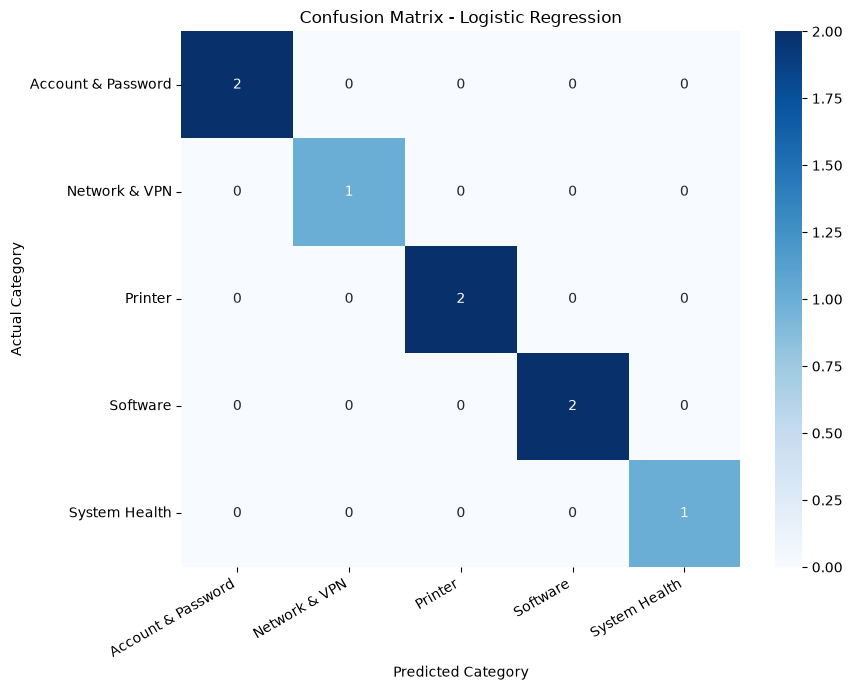

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Use the selected model's test predictions
class_labels = sorted(y_test.unique())

cm = confusion_matrix(
    y_test,
    test_predictions,
    labels=class_labels
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_labels,
    yticklabels=class_labels
)

plt.title("Confusion Matrix - Logistic Regression")
plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")
plt.xticks(rotation=30, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()

plt.show()


In [ ]:
# Category-wise Performance

In [6]:

from sklearn.metrics import classification_report

report = classification_report(
    y_test,
    test_predictions,
    labels=class_labels,
    output_dict=True,
    zero_division=0
)

category_performance = pd.DataFrame(report).T

category_performance = category_performance.loc[
    class_labels,
    ["precision", "recall", "f1-score", "support"]
]

display(category_performance.round(3))


,precision,recall,f1-score,support
Account & Password,1.0,1.0,1.0,2.0
Network & VPN,1.0,1.0,1.0,1.0
Printer,1.0,1.0,1.0,2.0
Software,1.0,1.0,1.0,2.0
System Health,1.0,1.0,1.0,1.0


In [ ]:
# Save Confusion Matrix

In [7]:
from pathlib import Path
import pandas as pd

RESULTS_DIR = Path(r"D:\AI_IT_HELPDESK\results")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

cm_df = pd.DataFrame(
    cm,
    index=[f"Actual_{x}" for x in class_labels],
    columns=[f"Predicted_{x}" for x in class_labels]
)

cm_df.to_csv(
    RESULTS_DIR / "confusion_matrix.csv"
)

category_performance.to_csv(
    RESULTS_DIR / "category_performance.csv"
)

print("Confusion matrix saved.")
print("Category performance saved.")

Confusion matrix saved.
Category performance saved.


In [ ]:
# Calculate Multiclass ROC-AUC

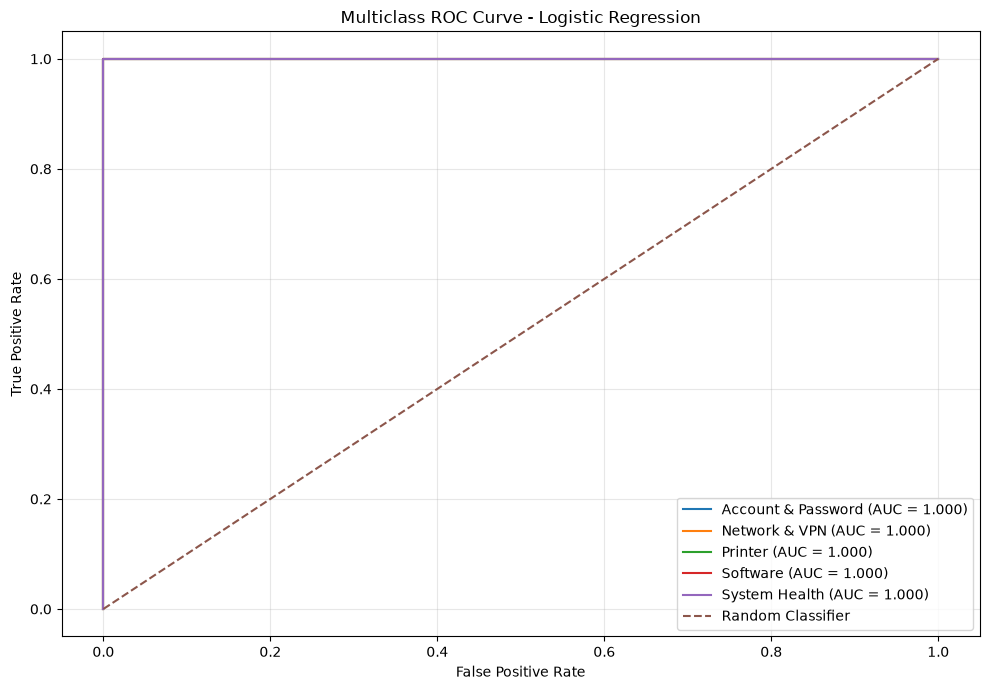

,Category,AUC
0,Account & Password,1.0
1,Network & VPN,1.0
2,Printer,1.0
3,Software,1.0
4,System Health,1.0


In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import label_binarize
from sklearn.metrics import (
    roc_curve,
    auc,
    roc_auc_score
)

# Obtain predicted probabilities from selected Logistic Regression model
y_prob = best_model.predict_proba(X_test)

# Use the model's actual class order
class_labels = best_model.classes_

# Convert actual labels into binary format
y_test_bin = label_binarize(
    y_test,
    classes=class_labels
)

# Calculate One-vs-Rest ROC curves
roc_results = []

plt.figure(figsize=(10, 7))

for i, category in enumerate(class_labels):

    fpr, tpr, thresholds = roc_curve(
        y_test_bin[:, i],
        y_prob[:, i]
    )

    category_auc = auc(fpr, tpr)

    roc_results.append({
        "Category": category,
        "AUC": category_auc
    })

    plt.plot(
        fpr,
        tpr,
        label=f"{category} (AUC = {category_auc:.3f})"
    )

# Random classifier reference line
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Multiclass ROC Curve - Logistic Regression")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

roc_results_df = pd.DataFrame(roc_results)

display(roc_results_df.round(4))


In [ ]:
# Calculate Overall AUC

In [9]:
macro_auc = roc_auc_score(
    y_test,
    y_prob,
    labels=class_labels,
    multi_class="ovr",
    average="macro"
)

weighted_auc = roc_auc_score(
    y_test,
    y_prob,
    labels=class_labels,
    multi_class="ovr",
    average="weighted"
)

print("===== ROC-AUC EVALUATION =====")
print("Macro OvR AUC:", round(macro_auc, 4))
print("Weighted OvR AUC:", round(weighted_auc, 4))


===== ROC-AUC EVALUATION =====
Macro OvR AUC: 1.0
Weighted OvR AUC: 1.0


In [ ]:
# Save ROC Results

In [10]:
from pathlib import Path

RESULTS_DIR = Path(r"D:\AI_IT_HELPDESK\results")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

roc_results_df.to_csv(
    RESULTS_DIR / "roc_auc_category_results.csv",
    index=False
)

overall_auc_df = pd.DataFrame([{
    "Model": best_model_name,
    "Macro_OvR_AUC": macro_auc,
    "Weighted_OvR_AUC": weighted_auc
}])

overall_auc_df.to_csv(
    RESULTS_DIR / "roc_auc_overall_results.csv",
    index=False
)

print("ROC-AUC results saved successfully.")
print("Location:", RESULTS_DIR)


ROC-AUC results saved successfully.
Location: D:\AI_IT_HELPDESK\results


In [ ]:
# Load Knowledge Base

In [11]:
from pathlib import Path
import pandas as pd

PROJECT_DIR = Path(r"D:\AI_IT_HELPDESK")

KB_PATH = PROJECT_DIR / "knowledge_base" / "it_knowledge_base.csv"

kb_df = pd.read_csv(KB_PATH)

print("Knowledge Base Records:", len(kb_df))
print("\nAvailable Columns:")
print(kb_df.columns.tolist())

display(kb_df.head(10))


Knowledge Base Records: 15

Available Columns:
['id', 'category', 'title', 'content', 'source']


,id,category,title,content,source
0,KB001,Account & Password,Windows Login Failure,\n Problem: User cannot log into Window...,Demo IT Support Knowledge Base
1,KB002,Account & Password,Password Reset,\n Problem: User forgot the Windows pas...,Demo IT Support Knowledge Base
2,KB003,Account & Password,Account Locked,\n Problem: Windows account is locked.\...,Demo IT Support Knowledge Base
3,KB004,Network & VPN,Internet Connection Failure,\n Problem: Computer cannot access the ...,Demo IT Support Knowledge Base
4,KB005,Network & VPN,VPN Connection Failure,\n Problem: User cannot connect to the ...,Demo IT Support Knowledge Base
5,KB006,Network & VPN,DNS Resolution Failure,\n Problem: DNS server is not respondin...,Demo IT Support Knowledge Base
6,KB007,Printer,Printer Offline,\n Problem: Network printer shows offli...,Demo IT Support Knowledge Base
7,KB008,Printer,Print Queue Stuck,\n Problem: Documents remain in the pri...,Demo IT Support Knowledge Base
8,KB009,Printer,Printer Driver Error,\n Problem: Printer driver is not funct...,Demo IT Support Knowledge Base
9,KB010,Software,Application Not Opening,\n Problem: Application fails to open.\...,Demo IT Support Knowledge Base


In [ ]:
# Check Knowledge Base IDs

In [12]:
print("Knowledge Base Article IDs:")

for column in kb_df.columns:
    if "id" in column.lower():
        print("\nID Column:", column)
        print(kb_df[column].tolist())

print("\nCategory Distribution:")

for column in kb_df.columns:
    if "category" in column.lower():
        print(kb_df[column].value_counts())


Knowledge Base Article IDs:

ID Column: id
['KB001', 'KB002', 'KB003', 'KB004', 'KB005', 'KB006', 'KB007', 'KB008', 'KB009', 'KB010', 'KB011', 'KB012', 'KB013', 'KB014', 'KB015']

Category Distribution:
category
Account & Password    3
Network & VPN         3
Printer               3
Software              3
System Health         3
Name: count, dtype: int64


In [ ]:
# Verify Existing Retrieval Function

In [18]:
print("Retrieval function available:",
      callable(globals().get("retrieve_knowledge")))

if callable(globals().get("retrieve_knowledge")):
    print("\nSample retrieval result:")
    sample_result = retrieve_knowledge(
        "How can I reset my Windows password?",
        top_k=3
    )
    print(sample_result)
else:
    print("Run the RAG setup and retrieval function cells first.")


Retrieval function available: False
Run the RAG setup and retrieval function cells first.


In [ ]:
#Prepare RAG Evaluation Dataset

In [19]:
# Display actual Knowledge Base articles

print("Knowledge Base Columns:")
print(kb_df.columns.tolist())

display(
    kb_df[["id", "title", "category"]]
    .sort_values("id")
    .reset_index(drop=True)
)


Knowledge Base Columns:
['id', 'category', 'title', 'content', 'source']


,id,title,category
0,KB001,Windows Login Failure,Account & Password
1,KB002,Password Reset,Account & Password
2,KB003,Account Locked,Account & Password
3,KB004,Internet Connection Failure,Network & VPN
4,KB005,VPN Connection Failure,Network & VPN
5,KB006,DNS Resolution Failure,Network & VPN
6,KB007,Printer Offline,Printer
7,KB008,Print Queue Stuck,Printer
8,KB009,Printer Driver Error,Printer
9,KB010,Application Not Opening,Software


In [ ]:
# Test Retrieval Ranking

In [21]:
from pathlib import Path
import chromadb
from sentence_transformers import SentenceTransformer

PROJECT_DIR = Path(r"D:\AI_IT_HELPDESK")

VECTOR_STORE_PATH = (
    PROJECT_DIR / "knowledge_base" / "vector_store"
)

# Load existing embedding model
embedding_model = SentenceTransformer(
    "sentence-transformers/all-MiniLM-L6-v2"
)

# Connect to existing ChromaDB
chroma_client = chromadb.PersistentClient(
    path=str(VECTOR_STORE_PATH)
)

# Load existing collection - do not recreate it
collection = chroma_client.get_collection(
    name="it_helpdesk_knowledge"
)

print("Embedding model loaded.")
print("Existing ChromaDB collection loaded.")
print("Total stored chunks:", collection.count())


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Embedding model loaded.
Existing ChromaDB collection loaded.
Total stored chunks: 15


In [23]:
def retrieve_knowledge(query, top_k=3):

    query_embedding = embedding_model.encode(
        [query]
    ).tolist()

    results = collection.query(
        query_embeddings=query_embedding,
        n_results=top_k,
        include=["documents", "metadatas", "distances"]
    )

    retrieved = []

    for i in range(len(results["ids"][0])):

        retrieved.append({
            "document_id": results["ids"][0][i],
            "content": results["documents"][0][i],
            "metadata": results["metadatas"][0][i],
            "distance": results["distances"][0][i]
        })

    return retrieved


print("Retrieval function ready:",
      callable(retrieve_knowledge))


Retrieval function ready: True


In [ ]:
#Test retrieval

In [24]:
query = "How can I reset my Windows password?"

expected_article_id = "KB002"

retrieved_results = retrieve_knowledge(
    query,
    top_k=5
)

retrieved_ids = [
    result["metadata"]["article_id"]
    for result in retrieved_results
]

print("Query:", query)
print("Expected Article:", expected_article_id)
print("Retrieved Articles:", retrieved_ids)

print("Recall@1:",
      expected_article_id in retrieved_ids[:1])

print("Recall@3:",
      expected_article_id in retrieved_ids[:3])

print("Recall@5:",
      expected_article_id in retrieved_ids[:5])


Query: How can I reset my Windows password?
Expected Article: KB002
Retrieved Articles: ['KB002', 'KB001', 'KB003', 'KB005', 'KB009']
Recall@1: True
Recall@3: True
Recall@5: True


In [25]:

query = "How can I reset my Windows password?"

expected_article_id = "KB002"

retrieved_results = retrieve_knowledge(
    query,
    top_k=5
)

retrieved_ids = [
    result["metadata"]["article_id"]
    for result in retrieved_results
]

print("Query:", query)
print("Expected Article:", expected_article_id)
print("Retrieved Articles:", retrieved_ids)

print(
    "Relevant article in Top 1:",
    expected_article_id in retrieved_ids[:1]
)

print(
    "Relevant article in Top 3:",
    expected_article_id in retrieved_ids[:3]
)

print(
    "Relevant article in Top 5:",
    expected_article_id in retrieved_ids[:5]
)


Query: How can I reset my Windows password?
Expected Article: KB002
Retrieved Articles: ['KB002', 'KB001', 'KB003', 'KB005', 'KB009']
Relevant article in Top 1: True
Relevant article in Top 3: True
Relevant article in Top 5: True


In [ ]:
# Create Evaluation Queries

In [26]:

import pandas as pd

rag_test_data = [
    {
        "query": "I cannot log into Windows. What should I check?",
        "expected_id": "KB001"
    },
    {
        "query": "How do I reset my forgotten Windows password?",
        "expected_id": "KB002"
    },
    {
        "query": "My Windows user account has been locked. How can it be unlocked?",
        "expected_id": "KB003"
    },
    {
        "query": "My computer cannot connect to the internet. How can I troubleshoot it?",
        "expected_id": "KB004"
    },
    {
        "query": "My VPN connection is failing. What should I check?",
        "expected_id": "KB005"
    },
    {
        "query": "Websites are not opening because of a DNS resolution problem.",
        "expected_id": "KB006"
    },
    {
        "query": "My network printer is offline. How can I fix it?",
        "expected_id": "KB007"
    },
    {
        "query": "My print jobs are stuck in the printer queue.",
        "expected_id": "KB008"
    },
    {
        "query": "The printer driver is not working correctly.",
        "expected_id": "KB009"
    },
    {
        "query": "An application does not open when I click it.",
        "expected_id": "KB010"
    },
    {
        "query": "How can I troubleshoot a software installation failure?",
        "expected_id": "KB011"
    },
    {
        "query": "My application keeps crashing. What should I do?",
        "expected_id": "KB012"
    },
    {
        "query": "My computer has unusually high CPU usage.",
        "expected_id": "KB013"
    },
    {
        "query": "My computer is running slowly because of high memory usage.",
        "expected_id": "KB014"
    },
    {
        "query": "My computer is running out of disk space.",
        "expected_id": "KB015"
    }
]

rag_eval_df = pd.DataFrame(rag_test_data)

print("Total evaluation queries:", len(rag_eval_df))
display(rag_eval_df)


Total evaluation queries: 15


,query,expected_id
0,I cannot log into Windows. What should I check?,KB001
1,How do I reset my forgotten Windows password?,KB002
2,My Windows user account has been locked. How c...,KB003
3,My computer cannot connect to the internet. Ho...,KB004
4,My VPN connection is failing. What should I ch...,KB005
5,Websites are not opening because of a DNS reso...,KB006
6,My network printer is offline. How can I fix it?,KB007
7,My print jobs are stuck in the printer queue.,KB008
8,The printer driver is not working correctly.,KB009
9,An application does not open when I click it.,KB010


In [ ]:
# Validate Ground Truth Article IDs

In [27]:
available_ids = set(kb_df["id"].astype(str))

rag_eval_df["ground_truth_exists"] = (
    rag_eval_df["expected_id"].isin(available_ids)
)

print("All expected articles available:",
      rag_eval_df["ground_truth_exists"].all())

print("Missing expected articles:",
      rag_eval_df.loc[
          ~rag_eval_df["ground_truth_exists"],
          "expected_id"
      ].tolist())

display(rag_eval_df)


All expected articles available: True
Missing expected articles: []


,query,expected_id,ground_truth_exists
0,I cannot log into Windows. What should I check?,KB001,True
1,How do I reset my forgotten Windows password?,KB002,True
2,My Windows user account has been locked. How c...,KB003,True
3,My computer cannot connect to the internet. Ho...,KB004,True
4,My VPN connection is failing. What should I ch...,KB005,True
5,Websites are not opening because of a DNS reso...,KB006,True
6,My network printer is offline. How can I fix it?,KB007,True
7,My print jobs are stuck in the printer queue.,KB008,True
8,The printer driver is not working correctly.,KB009,True
9,An application does not open when I click it.,KB010,True


In [ ]:
# Calculate Recall@K and MRR

In [28]:
import numpy as np

evaluation_results = []

for _, row in rag_eval_df.iterrows():

    query = row["query"]
    expected_id = row["expected_id"]

    results = retrieve_knowledge(
        query,
        top_k=5
    )

    retrieved_ids = [
        item["metadata"]["article_id"]
        for item in results
    ]

    # Find the first relevant article rank
    relevant_ranks = [
        rank
        for rank, article_id in enumerate(
            retrieved_ids, start=1
        )
        if article_id == expected_id
    ]

    first_rank = (
        relevant_ranks[0]
        if relevant_ranks else None
    )

    evaluation_results.append({
        "Query": query,
        "Expected_ID": expected_id,
        "Retrieved_IDs": ", ".join(retrieved_ids),
        "Rank": first_rank,
        "Recall@1": int(expected_id in retrieved_ids[:1]),
        "Recall@3": int(expected_id in retrieved_ids[:3]),
        "Recall@5": int(expected_id in retrieved_ids[:5]),
        "Reciprocal_Rank": (
            1 / first_rank if first_rank else 0
        )
    })

rag_results_df = pd.DataFrame(evaluation_results)

display(rag_results_df)

,Query,Expected_ID,Retrieved_IDs,Rank,Recall@1,Recall@3,Recall@5,Reciprocal_Rank
0,I cannot log into Windows. What should I check?,KB001,"KB001, KB003, KB002, KB010, KB005",1,1,1,1,1.0
1,How do I reset my forgotten Windows password?,KB002,"KB002, KB001, KB003, KB005, KB010",1,1,1,1,1.0
2,My Windows user account has been locked. How c...,KB003,"KB003, KB001, KB002, KB005, KB014",1,1,1,1,1.0
3,My computer cannot connect to the internet. Ho...,KB004,"KB004, KB006, KB005, KB007, KB001",1,1,1,1,1.0
4,My VPN connection is failing. What should I ch...,KB005,"KB005, KB006, KB004, KB011, KB012",1,1,1,1,1.0
5,Websites are not opening because of a DNS reso...,KB006,"KB006, KB004, KB010, KB005, KB012",1,1,1,1,1.0
6,My network printer is offline. How can I fix it?,KB007,"KB007, KB009, KB008, KB004, KB006",1,1,1,1,1.0
7,My print jobs are stuck in the printer queue.,KB008,"KB008, KB007, KB009, KB015, KB005",1,1,1,1,1.0
8,The printer driver is not working correctly.,KB009,"KB009, KB007, KB008, KB011, KB012",1,1,1,1,1.0
9,An application does not open when I click it.,KB010,"KB010, KB012, KB011, KB014, KB004",1,1,1,1,1.0


In [ ]:
# Overall RAG Metrics

In [29]:
rag_summary = pd.DataFrame([{
    "Total_Queries": len(rag_results_df),

    "Recall@1": rag_results_df["Recall@1"].mean(),

    "Recall@3": rag_results_df["Recall@3"].mean(),

    "Recall@5": rag_results_df["Recall@5"].mean(),

    "MRR": rag_results_df["Reciprocal_Rank"].mean()
}])

print("===== RAG RETRIEVAL EVALUATION =====")

display(rag_summary.round(4))

print("Recall@1:",
      f"{rag_summary.loc[0, 'Recall@1']:.2%}")

print("Recall@3:",
      f"{rag_summary.loc[0, 'Recall@3']:.2%}")

print("Recall@5:",
      f"{rag_summary.loc[0, 'Recall@5']:.2%}")

print("MRR:",
      round(rag_summary.loc[0, "MRR"], 4))


===== RAG RETRIEVAL EVALUATION =====


,Total_Queries,Recall@1,Recall@3,Recall@5,MRR
0,15,1.0,1.0,1.0,1.0


Recall@1: 100.00%
Recall@3: 100.00%
Recall@5: 100.00%
MRR: 1.0


In [ ]:
# Save Evaluation Results

In [30]:
from pathlib import Path

RESULTS_DIR = Path(r"D:\AI_IT_HELPDESK\results")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

rag_results_df.to_csv(
    RESULTS_DIR / "rag_detailed_evaluation.csv",
    index=False
)

rag_summary.to_csv(
    RESULTS_DIR / "rag_evaluation_summary.csv",
    index=False
)

print("RAG evaluation results saved.")
print("Location:", RESULTS_DIR)

RAG evaluation results saved.
Location: D:\AI_IT_HELPDESK\results


In [ ]:
# Load saved model evaluation results

In [31]:

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_DIR = Path(r"D:\AI_IT_HELPDESK")
RESULTS_DIR = PROJECT_DIR / "results"

validation_results_df = pd.read_csv(
    RESULTS_DIR / "classification_validation_results.csv"
)

test_results_df = pd.read_csv(
    RESULTS_DIR / "classification_test_results.csv"
)

print("Validation results loaded:")
display(validation_results_df.round(4))

print("Selected model test results:")
display(test_results_df.round(4))


Validation results loaded:


,Model,Accuracy,Precision,Recall,F1_Score
0,Logistic Regression,0.8571,0.9000,0.9,0.8667
1,Naive Bayes,0.8571,0.9000,0.9,0.8667
2,Linear SVM,0.8571,0.9000,0.9,0.8667
3,Random Forest,0.5714,0.5667,0.7,0.5667


Selected model test results:


,Selected_Model,Test_Accuracy,Test_Precision_Macro,Test_Recall_Macro,Test_F1_Macro
0,Logistic Regression,1.0,1.0,1.0,1.0


In [ ]:
# Model comparison chart

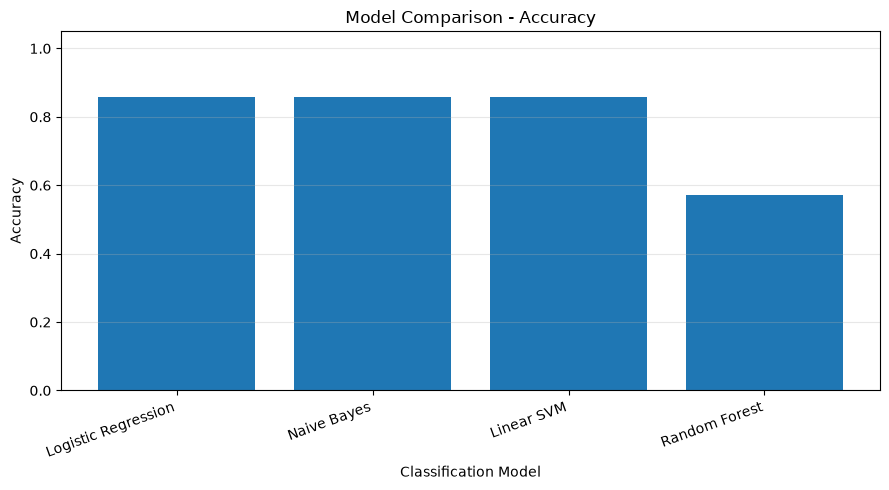

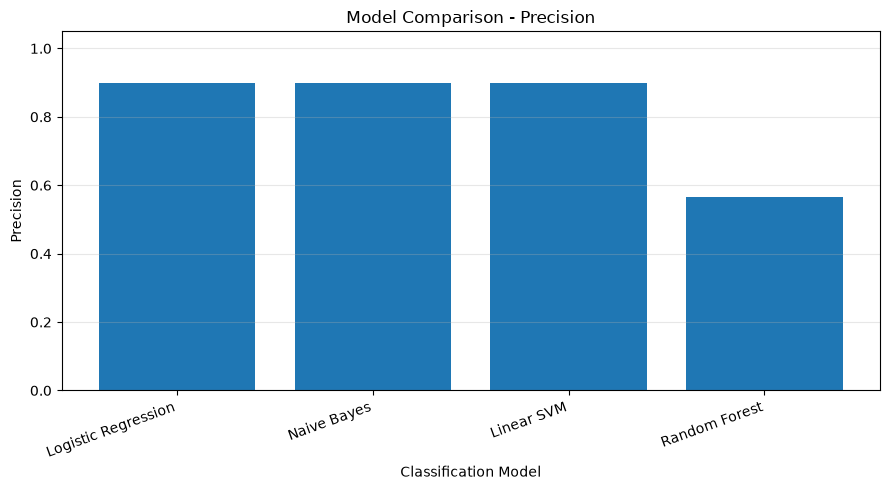

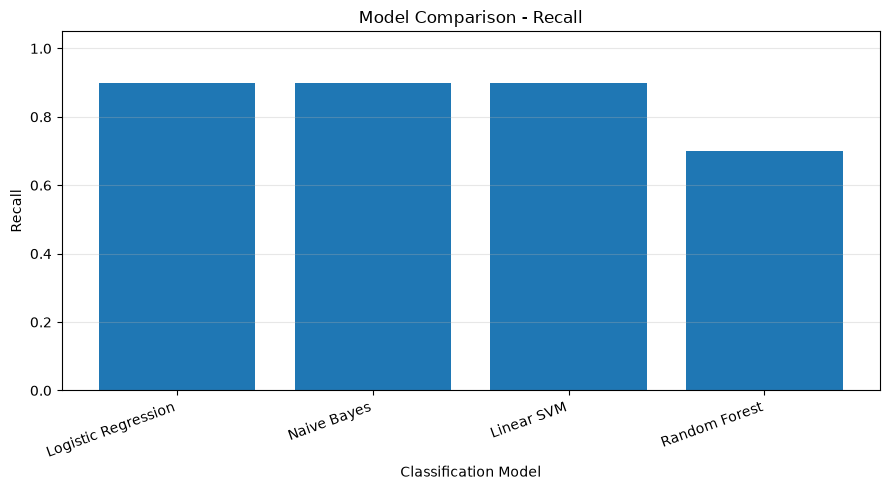

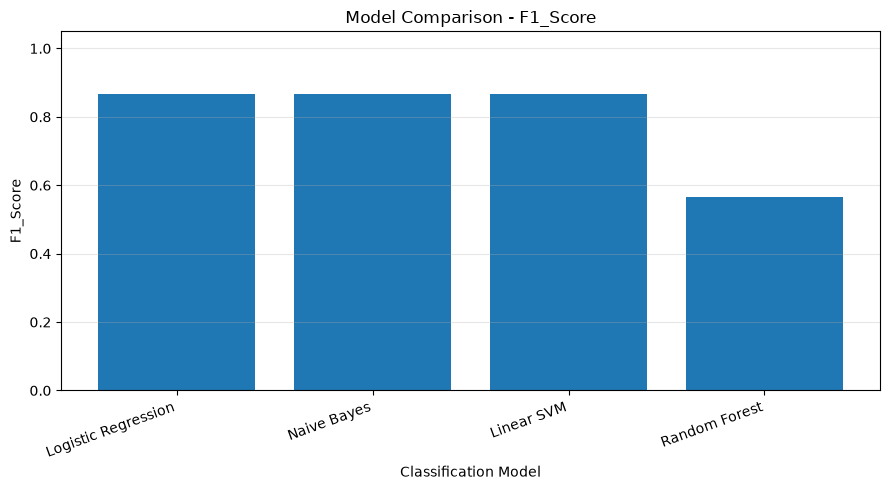

In [32]:

metrics = ["Accuracy", "Precision", "Recall", "F1_Score"]

for metric in metrics:

    plt.figure(figsize=(9, 5))

    plt.bar(
        validation_results_df["Model"],
        validation_results_df[metric]
    )

    plt.title(f"Model Comparison - {metric}")
    plt.xlabel("Classification Model")
    plt.ylabel(metric)
    plt.ylim(0, 1.05)
    plt.xticks(rotation=20, ha="right")
    plt.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.show()


In [ ]:
# Save comparison chart and final evaluation summary

In [33]:
# Save validation model comparison
validation_results_df.to_csv(
    RESULTS_DIR / "model_comparison.csv",
    index=False
)

# Combine classification and RAG evaluation metrics
rag_summary_df = pd.read_csv(
    RESULTS_DIR / "rag_evaluation_summary.csv"
)

final_summary = pd.DataFrame([
    {
        "Component": "Classification",
        "Metric": "Test Accuracy",
        "Value": float(test_results_df.iloc[0]["Test_Accuracy"])
    },
    {
        "Component": "Classification",
        "Metric": "Test Macro F1",
        "Value": float(test_results_df.iloc[0]["Test_F1_Macro"])
    },
    {
        "Component": "RAG",
        "Metric": "Recall@1",
        "Value": float(rag_summary_df.iloc[0]["Recall@1"])
    },
    {
        "Component": "RAG",
        "Metric": "Recall@3",
        "Value": float(rag_summary_df.iloc[0]["Recall@3"])
    },
    {
        "Component": "RAG",
        "Metric": "Recall@5",
        "Value": float(rag_summary_df.iloc[0]["Recall@5"])
    },
    {
        "Component": "RAG",
        "Metric": "MRR",
        "Value": float(rag_summary_df.iloc[0]["MRR"])
    }
])

final_summary.to_csv(
    RESULTS_DIR / "final_ai_evaluation_summary.csv",
    index=False
)

display(final_summary)

print("Final AI evaluation summary saved.")


,Component,Metric,Value
0,Classification,Test Accuracy,1.0
1,Classification,Test Macro F1,1.0
2,RAG,Recall@1,1.0
3,RAG,Recall@3,1.0
4,RAG,Recall@5,1.0
5,RAG,MRR,1.0


Final AI evaluation summary saved.


In [ ]:
# Database Integrity Testing

In [34]:
import sqlite3
import pandas as pd
from pathlib import Path

DB_PATH = Path(
    r"D:\AI_IT_HELPDESK\database\helpdesk.db"
)

if not DB_PATH.exists():
    raise FileNotFoundError(
        f"Database not found: {DB_PATH}"
    )

# Open database in read-only mode
conn = sqlite3.connect(
    f"file:{DB_PATH.as_posix()}?mode=ro",
    uri=True
)

tables_df = pd.read_sql_query("""
    SELECT name AS table_name
    FROM sqlite_master
    WHERE type = 'table'
    ORDER BY name
""", conn)

print("===== DATABASE TABLES =====")
display(tables_df)

conn.close()


===== DATABASE TABLES =====


,table_name
0,audit_logs
1,categories
2,conversations
3,knowledge_base
4,sqlite_sequence
5,ticket_attachments
6,ticket_comments
7,tickets
8,users


In [ ]:
# Verify Required Tables and Columns

In [35]:
import sqlite3
import pandas as pd

DB_PATH = r"D:\AI_IT_HELPDESK\database\helpdesk.db"

required_schema = {
    "users": [
        "user_id", "username", "email", "role"
    ],
    "tickets": [
        "ticket_id", "user_id", "title",
        "description", "category_id",
        "priority", "status", "assigned_to"
    ],
    "ticket_comments": [
        "comment_id", "ticket_id",
        "user_id", "comment", "created_at"
    ],
    "audit_logs": [
        "log_id", "user_id", "ticket_id",
        "action", "details", "created_at"
    ]
}

conn = sqlite3.connect(
    f"file:{DB_PATH.replace(chr(92), '/')}?mode=ro",
    uri=True
)

schema_results = []

for table, required_columns in required_schema.items():

    table_info = pd.read_sql_query(
        f'PRAGMA table_info("{table}")',
        conn
    )

    actual_columns = set(table_info["name"])

    missing_columns = [
        col for col in required_columns
        if col not in actual_columns
    ]

    schema_results.append({
        "Table": table,
        "Exists": not table_info.empty,
        "Missing_Columns": ", ".join(missing_columns),
        "Status": (
            "PASS"
            if not table_info.empty and not missing_columns
            else "CHECK"
        )
    })

conn.close()

schema_results_df = pd.DataFrame(schema_results)

display(schema_results_df)

print(
    "Tables passed:",
    (schema_results_df["Status"] == "PASS").sum()
)

,Table,Exists,Missing_Columns,Status
0,users,True,,PASS
1,tickets,True,,PASS
2,ticket_comments,True,,PASS
3,audit_logs,True,,PASS


Tables passed: 4


In [ ]:
# Database Record Summary

In [36]:
import sqlite3
import pandas as pd

DB_PATH = r"D:\AI_IT_HELPDESK\database\helpdesk.db"

conn = sqlite3.connect(
    f"file:{DB_PATH.replace(chr(92), '/')}?mode=ro",
    uri=True
)

summary_queries = {
    "Users": "SELECT COUNT(*) AS total FROM users",
    "Tickets": "SELECT COUNT(*) AS total FROM tickets",
    "Comments": "SELECT COUNT(*) AS total FROM ticket_comments",
    "Audit Logs": "SELECT COUNT(*) AS total FROM audit_logs"
}

for name, query in summary_queries.items():

    result = pd.read_sql_query(query, conn)

    print(f"{name}: {result.iloc[0]['total']}")

conn.close()


Users: 4
Tickets: 5
Comments: 1
Audit Logs: 9


In [ ]:
# Verify User Roles

In [37]:
import sqlite3
import pandas as pd

DB_PATH = r"D:\AI_IT_HELPDESK\database\helpdesk.db"

conn = sqlite3.connect(
    f"file:{DB_PATH.replace(chr(92), '/')}?mode=ro",
    uri=True
)

users_df = pd.read_sql_query("""
    SELECT
        user_id,
        username,
        email,
        role
    FROM users
    ORDER BY user_id
""", conn)

print("===== USER ROLE VERIFICATION =====")
display(users_df)

print("\nRole Distribution:")
display(
    users_df.groupby("role")
    .size()
    .reset_index(name="Total Users")
)

conn.close()


===== USER ROLE VERIFICATION =====


,user_id,username,email,role
0,1,admin,admin@admin.com,admin
1,2,user,user@admin.com,user
2,3,suser,suser@email.com,support
3,4,nimesh,nimesh91.nimesh@gmail.com,support



Role Distribution:


,role,Total Users
0,admin,1
1,support,2
2,user,1


In [ ]:
# Verify Ticket Ownership and Assignment

In [38]:
import sqlite3
import pandas as pd

DB_PATH = r"D:\AI_IT_HELPDESK\database\helpdesk.db"

conn = sqlite3.connect(
    f"file:{DB_PATH.replace(chr(92), '/')}?mode=ro",
    uri=True
)

ticket_access_df = pd.read_sql_query("""
    SELECT
        t.ticket_id,
        t.title,
        creator.username AS created_by,
        creator.role AS creator_role,
        support.username AS assigned_to,
        support.role AS assigned_role,
        t.status,
        t.priority
    FROM tickets t
    LEFT JOIN users creator
        ON t.user_id = creator.user_id
    LEFT JOIN users support
        ON t.assigned_to = support.user_id
    ORDER BY t.ticket_id
""", conn)

display(ticket_access_df)

conn.close()


,ticket_id,title,created_by,creator_role,assigned_to,assigned_role,status,priority
0,1,Printer is offline,NaN,NaN,NaN,NaN,Open,Medium
1,2,printer not working,NaN,NaN,NaN,NaN,Open,Low
2,3,my account not working,user,user,NaN,NaN,Open,High
3,4,scanner not working,admin,admin,nimesh,support,In Progress,Medium
4,5,printer not working,nimesh,support,nimesh,support,Resolved,Medium


In [ ]:
# Automated Role Assignment Checks

In [39]:
role_checks = []

# Admin account check
role_checks.append({
    "Test": "Admin account exists",
    "Result": (users_df["role"] == "admin").any()
})

# Normal user account check
role_checks.append({
    "Test": "Normal user account exists",
    "Result": (users_df["role"] == "user").any()
})

# Support account check
role_checks.append({
    "Test": "Support account exists",
    "Result": (users_df["role"] == "support").any()
})

# Assigned tickets must belong to support staff
assigned_tickets = ticket_access_df[
    ticket_access_df["assigned_to"].notna()
]

role_checks.append({
    "Test": "All assigned tickets belong to support staff",
    "Result": (
        (assigned_tickets["assigned_role"] == "support").all()
        if not assigned_tickets.empty
        else True
    )
})

role_check_df = pd.DataFrame(role_checks)

role_check_df["Status"] = role_check_df["Result"].map({
    True: "PASS",
    False: "CHECK"
})

display(role_check_df)

,Test,Result,Status
0,Admin account exists,True,PASS
1,Normal user account exists,True,PASS
2,Support account exists,True,PASS
3,All assigned tickets belong to support staff,True,PASS


In [ ]:
# Verify User Ticket Access

In [40]:
import sqlite3
import pandas as pd

DB_PATH = r"D:\AI_IT_HELPDESK\database\helpdesk.db"

conn = sqlite3.connect(
    f"file:{DB_PATH.replace(chr(92), '/')}?mode=ro",
    uri=True
)

user_access = pd.read_sql_query("""
    SELECT
        u.username,
        u.user_id,
        COUNT(t.ticket_id) AS owned_tickets
    FROM users u
    LEFT JOIN tickets t
        ON t.user_id = u.user_id
    WHERE u.role = 'user'
    GROUP BY u.user_id, u.username
""", conn)

support_access = pd.read_sql_query("""
    SELECT
        u.username,
        u.user_id,
        COUNT(t.ticket_id) AS assigned_tickets
    FROM users u
    LEFT JOIN tickets t
        ON t.assigned_to = u.user_id
    WHERE u.role = 'support'
    GROUP BY u.user_id, u.username
""", conn)

print("===== NORMAL USER TICKET OWNERSHIP =====")
display(user_access)

print("===== SUPPORT STAFF ASSIGNMENTS =====")
display(support_access)

conn.close()


===== NORMAL USER TICKET OWNERSHIP =====


,username,user_id,owned_tickets
0,user,2,1


===== SUPPORT STAFF ASSIGNMENTS =====


,username,user_id,assigned_tickets
0,suser,3,0
1,nimesh,4,2


In [ ]:
# Verify Unauthorized Assignment

In [41]:
import sqlite3
import pandas as pd

DB_PATH = r"D:\AI_IT_HELPDESK\database\helpdesk.db"

conn = sqlite3.connect(
    f"file:{DB_PATH.replace(chr(92), '/')}?mode=ro",
    uri=True
)

invalid_assignments = pd.read_sql_query("""
    SELECT
        t.ticket_id,
        t.title,
        u.username AS assigned_to,
        u.role AS assigned_role
    FROM tickets t
    JOIN users u
        ON t.assigned_to = u.user_id
    WHERE u.role != 'support'
""", conn)

conn.close()

print("===== INVALID TICKET ASSIGNMENTS =====")
display(invalid_assignments)

if invalid_assignments.empty:
    print("PASS: No tickets assigned to non-support accounts.")
else:
    print("CHECK: Review the assignments listed above.")


===== INVALID TICKET ASSIGNMENTS =====


,ticket_id,title,assigned_to,assigned_role


PASS: No tickets assigned to non-support accounts.


In [ ]:
# Final Ticket Workflow Database Verification

In [42]:
import sqlite3
import pandas as pd

DB_PATH = r"D:\AI_IT_HELPDESK\database\helpdesk.db"

conn = sqlite3.connect(
    f"file:{DB_PATH.replace(chr(92), '/')}?mode=ro",
    uri=True
)

ticket_id = 6

ticket_result = pd.read_sql_query("""
    SELECT
        t.ticket_id,
        t.title,
        creator.username AS created_by,
        support.username AS assigned_to,
        t.status,
        t.priority,
        t.created_at,
        t.first_response_at,
        t.resolved_at,
        t.response_due_at,
        t.resolution_due_at
    FROM tickets t
    LEFT JOIN users creator
        ON t.user_id = creator.user_id
    LEFT JOIN users support
        ON t.assigned_to = support.user_id
    WHERE t.ticket_id = ?
""", conn, params=(ticket_id,))

comments_result = pd.read_sql_query("""
    SELECT
        c.comment_id,
        u.username,
        u.role,
        c.comment,
        c.created_at
    FROM ticket_comments c
    JOIN users u ON c.user_id = u.user_id
    WHERE c.ticket_id = ?
    ORDER BY c.created_at
""", conn, params=(ticket_id,))

audit_result = pd.read_sql_query("""
    SELECT
        a.log_id,
        u.username,
        a.action,
        a.details,
        a.created_at
    FROM audit_logs a
    LEFT JOIN users u ON a.user_id = u.user_id
    WHERE a.ticket_id = ?
    ORDER BY a.created_at
""", conn, params=(ticket_id,))

conn.close()

print("===== TICKET DETAILS =====")
display(ticket_result)

print("===== TICKET COMMENTS =====")
display(comments_result)

print("===== TICKET AUDIT HISTORY =====")
display(audit_result)


===== TICKET DETAILS =====


,ticket_id,title,created_by,assigned_to,status,priority,created_at,first_response_at,resolved_at,response_due_at,resolution_due_at
0,6,my pc internet not working,user,nimesh,Resolved,Medium,2026-11-03 08:57:21,2026-11-03 09:06:53,2026-11-03 09:07:36,2026-11-03 13:03:02,2026-11-04 09:03:02


===== TICKET COMMENTS =====


,comment_id,username,role,comment,created_at
0,2,nimesh,support,issue fixing,2026-11-03 09:06:53


===== TICKET AUDIT HISTORY =====


,log_id,username,action,details,created_at
0,10,user,TICKET_CREATED,Created by user: my pc internet not working,2026-11-03 08:57:21
1,11,admin,TICKET_UPDATED,Status: Open -> Open; Priority: Medium -> Medi...,2026-11-03 09:03:02
2,12,nimesh,SUPPORT_TICKET_STATUS_UPDATED,Status changed to In Progress,2026-11-03 09:04:35
3,13,nimesh,TICKET_COMMENTED,Comment added to ticket: my pc internet not wo...,2026-11-03 09:06:53
4,14,nimesh,SUPPORT_TICKET_STATUS_UPDATED,Status changed to Resolved,2026-11-03 09:07:36


In [ ]:
# Load evaluation result files

In [43]:
from pathlib import Path
import pandas as pd

PROJECT_DIR = Path(r"D:\AI_IT_HELPDESK")
RESULTS_DIR = PROJECT_DIR / "results"

print("===== PROJECT EVALUATION FILES =====")

for file in sorted(RESULTS_DIR.glob("*.csv")):
    print(file.name)

===== PROJECT EVALUATION FILES =====
category_performance.csv
classification_test_results.csv
classification_validation_results.csv
confusion_matrix.csv
final_ai_evaluation_summary.csv
final_model_evaluation.csv
model_comparison.csv
rag_detailed_evaluation.csv
rag_evaluation_summary.csv
rag_retrieval_evaluation.csv
roc_auc_category_results.csv
roc_auc_overall_results.csv
sample_predictions.csv


In [ ]:
# Load important evaluation results

In [44]:
result_files = {
    "Classification Validation":
        "classification_validation_results.csv",

    "Classification Test":
        "classification_test_results.csv",

    "Final Model Evaluation":
        "final_model_evaluation.csv",

    "Final AI Evaluation Summary":
        "final_ai_evaluation_summary.csv",

    "RAG Evaluation Summary":
        "rag_evaluation_summary.csv",

    "RAG Retrieval Evaluation":
        "rag_retrieval_evaluation.csv",

    "Category Performance":
        "category_performance.csv",

    "ROC-AUC Results":
        "roc_auc_category_results.csv"
}

evaluation_data = {}

for name, filename in result_files.items():

    file_path = RESULTS_DIR / filename

    if file_path.exists():
        df = pd.read_csv(file_path)
        evaluation_data[name] = df

        print(f"\n===== {name} =====")
        display(df.head(10))

    else:
        print(f"\nNot found: {filename}")



===== Classification Validation =====


,Model,Accuracy,Precision,Recall,F1_Score
0,Logistic Regression,0.857143,0.900000,0.9,0.866667
1,Naive Bayes,0.857143,0.900000,0.9,0.866667
2,Linear SVM,0.857143,0.900000,0.9,0.866667
3,Random Forest,0.571429,0.566667,0.7,0.566667



===== Classification Test =====


,Selected_Model,Test_Accuracy,Test_Precision_Macro,Test_Recall_Macro,Test_F1_Macro
0,Logistic Regression,1.0,1.0,1.0,1.0



===== Final Model Evaluation =====


,Selected_Model,Test_Accuracy,Test_Precision_Macro,Test_Recall_Macro,Test_F1_Macro,Training_Records,Testing_Records
0,Logistic Regression,1.0,1.0,1.0,1.0,42,8


... (6 outputs left out)


===== Category Performance =====


,Unnamed: 0,precision,recall,f1-score,support
0,Account & Password,1.0,1.0,1.0,2.0
1,Network & VPN,1.0,1.0,1.0,1.0
2,Printer,1.0,1.0,1.0,2.0
3,Software,1.0,1.0,1.0,2.0
4,System Health,1.0,1.0,1.0,1.0



===== ROC-AUC Results =====


,Category,AUC
0,Account & Password,1.0
1,Network & VPN,1.0
2,Printer,1.0
3,Software,1.0
4,System Health,1.0


In [ ]:
# Check the evaluation data

In [45]:
print("===== EVALUATION FILE CHECK =====")

for name, df in evaluation_data.items():

    print(
        f"{name}: "
        f"{len(df)} records | "
        f"{len(df.columns)} columns"
    )

print("\nTotal evaluation files loaded:", len(evaluation_data))


===== EVALUATION FILE CHECK =====
Classification Validation: 4 records | 5 columns
Classification Test: 1 records | 5 columns
Final Model Evaluation: 1 records | 7 columns
Final AI Evaluation Summary: 6 records | 3 columns
RAG Evaluation Summary: 1 records | 5 columns
RAG Retrieval Evaluation: 5 records | 4 columns
Category Performance: 5 records | 5 columns
ROC-AUC Results: 5 records | 2 columns

Total evaluation files loaded: 8


In [ ]:
# Connect to database and inspect ticket columns

In [46]:
import sqlite3
import pandas as pd
from pathlib import Path

PROJECT_DIR = Path(r"D:\AI_IT_HELPDESK")
DB_PATH = PROJECT_DIR / "database" / "helpdesk.db"

conn = sqlite3.connect(DB_PATH)

ticket_columns = pd.read_sql_query(
    "PRAGMA table_info(tickets)",
    conn
)

display(ticket_columns[["name", "type"]])

print("Database connected successfully.")


,name,type
0,ticket_id,INTEGER
1,user_id,INTEGER
2,title,TEXT
3,description,TEXT
4,category_id,INTEGER
5,priority,TEXT
6,status,TEXT
7,created_at,DATETIME
8,updated_at,DATETIME
9,assigned_to,INTEGER


Database connected successfully.


In [ ]:
# Ticket status analysis

In [47]:

ticket_summary = pd.read_sql_query("""
SELECT
    status,
    COUNT(*) AS total_tickets
FROM tickets
GROUP BY status
ORDER BY status
""", conn)

display(ticket_summary)

total_tickets = pd.read_sql_query(
    "SELECT COUNT(*) AS total FROM tickets",
    conn
).iloc[0]["total"]

print("Total Tickets:", total_tickets)


,status,total_tickets
0,In Progress,1
1,Open,3
2,Resolved,2


Total Tickets: 6


In [ ]:
# First response and resolution time

In [48]:

time_analysis = pd.read_sql_query("""
SELECT
    ticket_id,
    title,
    status,
    created_at,
    first_response_at,
    resolved_at,

    CASE
        WHEN first_response_at IS NOT NULL
        THEN ROUND(
            (julianday(first_response_at) -
             julianday(created_at)) * 24 * 60,
            2
        )
        ELSE NULL
    END AS first_response_minutes,

    CASE
        WHEN resolved_at IS NOT NULL
        THEN ROUND(
            (julianday(resolved_at) -
             julianday(created_at)) * 24 * 60,
            2
        )
        ELSE NULL
    END AS resolution_minutes

FROM tickets
ORDER BY ticket_id DESC
""", conn)

display(time_analysis)

print(
    "Average FRT (minutes):",
    round(time_analysis["first_response_minutes"].mean(), 2)
)

print(
    "Average Resolution Time (minutes):",
    round(time_analysis["resolution_minutes"].mean(), 2)
)


,ticket_id,title,status,created_at,first_response_at,resolved_at,first_response_minutes,resolution_minutes
0,6,my pc internet not working,Resolved,2026-11-03 08:57:21,2026-11-03 09:06:53,2026-11-03 09:07:36,9.53,10.25
1,5,printer not working,Resolved,2026-11-03 05:28:44,NaN,2026-11-03 06:19:04,NaN,50.33
2,4,scanner not working,In Progress,2026-11-02 10:15:57,NaN,NaN,NaN,NaN
3,3,my account not working,Open,2026-11-02 10:14:56,NaN,NaN,NaN,NaN
4,2,printer not working,Open,2026-11-02 09:22:50,NaN,NaN,NaN,NaN
5,1,Printer is offline,Open,2026-11-02 09:12:43,NaN,NaN,NaN,NaN


Average FRT (minutes): 9.53
Average Resolution Time (minutes): 30.29


In [ ]:
# SLA compliance

In [49]:

sla_analysis = pd.read_sql_query("""
SELECT
    COUNT(*) AS total_tickets,

    SUM(
        CASE
            WHEN first_response_at IS NOT NULL
            THEN 1 ELSE 0
        END
    ) AS responded_tickets,

    SUM(
        CASE
            WHEN first_response_at IS NOT NULL
             AND response_due_at IS NOT NULL
             AND first_response_at <= response_due_at
            THEN 1 ELSE 0
        END
    ) AS response_sla_met,

    SUM(
        CASE
            WHEN resolved_at IS NOT NULL
            THEN 1 ELSE 0
        END
    ) AS resolved_tickets,

    SUM(
        CASE
            WHEN resolved_at IS NOT NULL
             AND resolution_due_at IS NOT NULL
             AND resolved_at <= resolution_due_at
            THEN 1 ELSE 0
        END
    ) AS resolution_sla_met

FROM tickets
""", conn)

display(sla_analysis)

conn.close()


,total_tickets,responded_tickets,response_sla_met,resolved_tickets,resolution_sla_met
0,6,1,1,2,2


In [ ]:
# Create combined performance summary

In [50]:
from pathlib import Path
import sqlite3
import pandas as pd

PROJECT_DIR = Path(r"D:\AI_IT_HELPDESK")
RESULTS_DIR = PROJECT_DIR / "results"
DB_PATH = PROJECT_DIR / "database" / "helpdesk.db"

# Load existing AI evaluation results
final_model = pd.read_csv(
    RESULTS_DIR / "final_model_evaluation.csv"
)

rag_summary = pd.read_csv(
    RESULTS_DIR / "rag_evaluation_summary.csv"
)

# Connect to database
conn = sqlite3.connect(DB_PATH)

tickets = pd.read_sql_query(
    "SELECT * FROM tickets",
    conn
)

conn.close()

# Calculate ticket metrics
tickets["created_at"] = pd.to_datetime(
    tickets["created_at"], errors="coerce"
)

tickets["first_response_at"] = pd.to_datetime(
    tickets["first_response_at"], errors="coerce"
)

tickets["resolved_at"] = pd.to_datetime(
    tickets["resolved_at"], errors="coerce"
)

frt = (
    tickets["first_response_at"] -
    tickets["created_at"]
).dt.total_seconds() / 60

resolution = (
    tickets["resolved_at"] -
    tickets["created_at"]
).dt.total_seconds() / 60

response_evaluable = (
    tickets["first_response_at"].notna()
)

resolution_evaluable = (
    tickets["resolved_at"].notna()
)

response_met = (
    response_evaluable &
    (tickets["first_response_at"] <=
     pd.to_datetime(tickets["response_due_at"], errors="coerce"))
)

resolution_met = (
    resolution_evaluable &
    (tickets["resolved_at"] <=
     pd.to_datetime(tickets["resolution_due_at"], errors="coerce"))
)

response_compliance = (
    response_met.sum() / response_evaluable.sum() * 100
    if response_evaluable.sum() else 0
)

resolution_compliance = (
    resolution_met.sum() / resolution_evaluable.sum() * 100
    if resolution_evaluable.sum() else 0
)

# Combined report
report = pd.DataFrame([
    ["Classification", "Model", final_model.iloc[0]["Selected_Model"]],
    ["Classification", "Test Accuracy (%)",
     final_model.iloc[0]["Test_Accuracy"] * 100],
    ["Classification", "Test Macro F1 (%)",
     final_model.iloc[0]["Test_F1_Macro"] * 100],
    ["RAG", "Total Evaluation Queries",
     rag_summary.iloc[0]["Total_Queries"]],
    ["RAG", "Recall@1 (%)",
     rag_summary.iloc[0]["Recall@1"] * 100],
    ["RAG", "Recall@3 (%)",
     rag_summary.iloc[0]["Recall@3"] * 100],
    ["RAG", "Recall@5 (%)",
     rag_summary.iloc[0]["Recall@5"] * 100],
    ["RAG", "MRR",
     rag_summary.iloc[0]["MRR"]],
    ["Ticket Management", "Total Tickets", len(tickets)],
    ["Ticket Management", "Resolved Tickets",
     (tickets["status"] == "Resolved").sum()],
    ["Ticket Management", "Open Tickets",
     (tickets["status"] == "Open").sum()],
    ["Ticket Management", "In Progress Tickets",
     (tickets["status"] == "In Progress").sum()],
    ["Performance", "Average FRT (Minutes)", frt.mean()],
    ["Performance", "Average Resolution (Minutes)",
     resolution.mean()],
    ["SLA", "Response Compliance (%)", response_compliance],
    ["SLA", "Resolution Compliance (%)", resolution_compliance]
], columns=["Component", "Metric", "Value"])

display(report.round(2))

# Save report
report.to_csv(
    RESULTS_DIR / "combined_system_evaluation.csv",
    index=False
)

print("\nCombined evaluation report saved successfully.")
print("Location:", RESULTS_DIR)


,Component,Metric,Value
0,Classification,Model,Logistic Regression
1,Classification,Test Accuracy (%),100.0
2,Classification,Test Macro F1 (%),100.0
3,RAG,Total Evaluation Queries,15.0
4,RAG,Recall@1 (%),100.0
5,RAG,Recall@3 (%),100.0
6,RAG,Recall@5 (%),100.0
7,RAG,MRR,1.0
8,Ticket Management,Total Tickets,6
9,Ticket Management,Resolved Tickets,2



Combined evaluation report saved successfully.
Location: D:\AI_IT_HELPDESK\results


In [ ]:
# Generate ticket status chart

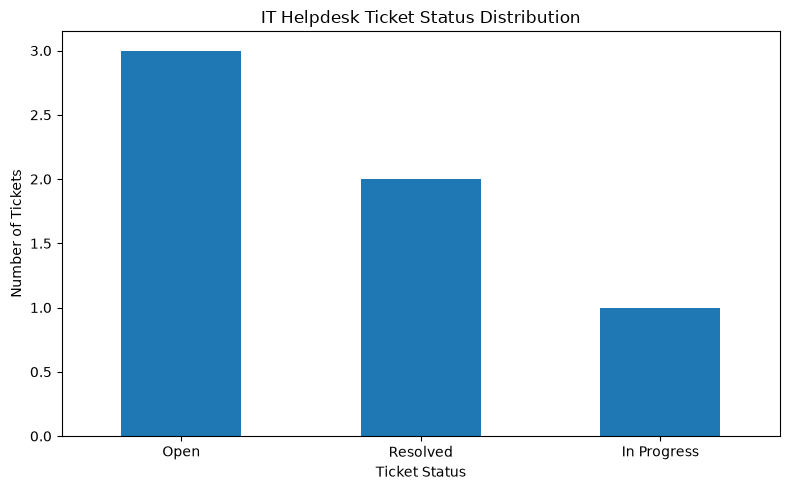

In [51]:
import matplotlib.pyplot as plt

status_counts = tickets["status"].value_counts()

plt.figure(figsize=(8, 5))

status_counts.plot(
    kind="bar",
    title="IT Helpdesk Ticket Status Distribution"
)

plt.xlabel("Ticket Status")
plt.ylabel("Number of Tickets")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "ticket_status_distribution.png",
    dpi=300
)

plt.show()


In [ ]:
# Generate performance chart

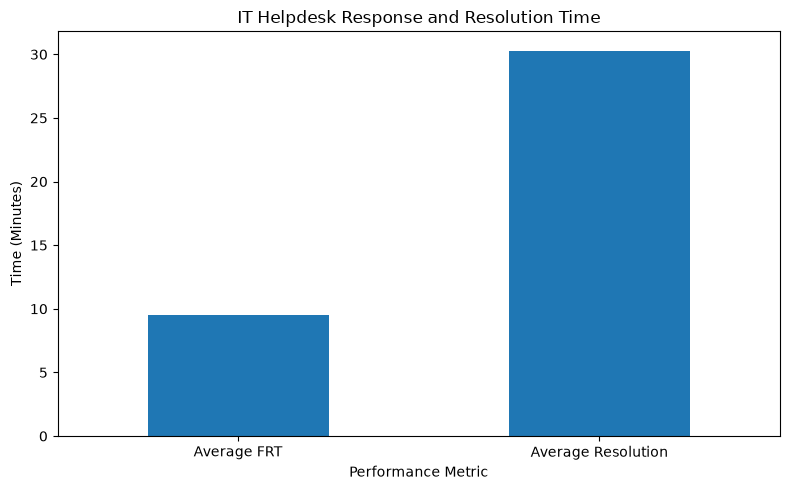

Performance charts saved successfully.


In [52]:
performance_metrics = pd.Series({
    "Average FRT": frt.mean(),
    "Average Resolution": resolution.mean()
})

plt.figure(figsize=(8, 5))

performance_metrics.plot(
    kind="bar",
    title="IT Helpdesk Response and Resolution Time"
)

plt.ylabel("Time (Minutes)")
plt.xlabel("Performance Metric")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "ticket_performance_comparison.png",
    dpi=300
)

plt.show()

print("Performance charts saved successfully.")

In [ ]:
# Create UAT testing dataset

In [53]:
from pathlib import Path
import pandas as pd

PROJECT_DIR = Path(r"D:\AI_IT_HELPDESK")
RESULTS_DIR = PROJECT_DIR / "results"

RESULTS_DIR.mkdir(parents=True, exist_ok=True)

test_cases = [
    ["TC001", "Authentication", "Login with valid admin credentials",
     "Admin login successful"],
    ["TC002", "Authentication", "Login with valid user credentials",
     "User login successful"],
    ["TC003", "Authentication", "Login with invalid password",
     "Access denied"],
    ["TC004", "RBAC", "User accesses Admin Dashboard",
     "Access restricted"],
    ["TC005", "RBAC", "Support staff accesses Support Dashboard",
     "Assigned tickets displayed"],
    ["TC006", "RBAC", "User accesses another user's ticket",
     "Access restricted"],
    ["TC007", "AI Classification", "Submit printer-related issue",
     "Printer category predicted"],
    ["TC008", "AI Classification", "Submit password-related issue",
     "Account & Password predicted"],
    ["TC009", "AI Classification", "Submit network-related issue",
     "Network & VPN predicted"],
    ["TC010", "RAG", "Search Windows password solution",
     "Relevant KB article retrieved"],
    ["TC011", "RAG", "Search printer troubleshooting solution",
     "Relevant KB article retrieved"],
    ["TC012", "Ticket Management", "User creates a new ticket",
     "Ticket saved in database"],
    ["TC013", "Ticket Management", "User views My Tickets",
     "Only own tickets displayed"],
    ["TC014", "Ticket Management", "Admin assigns ticket to support staff",
     "Assignment updated"],
    ["TC015", "Ticket Management", "Support staff updates ticket status",
     "Status updated"],
    ["TC016", "Ticket Management", "Support staff adds ticket comment",
     "Comment saved and displayed"],
    ["TC017", "SLA", "Check ticket response SLA",
     "Correct response SLA status displayed"],
    ["TC018", "SLA", "Check ticket resolution SLA",
     "Correct resolution SLA status displayed"],
    ["TC019", "Audit Logging", "Perform ticket activity",
     "Activity recorded in audit log"],
    ["TC020", "Dashboard", "Admin views performance dashboard",
     "Performance metrics displayed"]
]

uat_df = pd.DataFrame(
    test_cases,
    columns=[
        "Test_ID",
        "Module",
        "Test_Scenario",
        "Expected_Result"
    ]
)

uat_df["Actual_Result"] = ""
uat_df["Status"] = "Pending"
uat_df["Remarks"] = ""

display(uat_df)

uat_path = RESULTS_DIR / "UAT_test_cases.csv"

uat_df.to_csv(uat_path, index=False)

print("\nUAT test cases created successfully.")
print("Total test cases:", len(uat_df))
print("Saved:", uat_path)


,Test_ID,Module,Test_Scenario,Expected_Result,Actual_Result,Status,Remarks
0,TC001,Authentication,Login with valid admin credentials,Admin login successful,,Pending,
1,TC002,Authentication,Login with valid user credentials,User login successful,,Pending,
2,TC003,Authentication,Login with invalid password,Access denied,,Pending,
3,TC004,RBAC,User accesses Admin Dashboard,Access restricted,,Pending,
4,TC005,RBAC,Support staff accesses Support Dashboard,Assigned tickets displayed,,Pending,
5,TC006,RBAC,User accesses another user's ticket,Access restricted,,Pending,
6,TC007,AI Classification,Submit printer-related issue,Printer category predicted,,Pending,
7,TC008,AI Classification,Submit password-related issue,Account & Password predicted,,Pending,
8,TC009,AI Classification,Submit network-related issue,Network & VPN predicted,,Pending,
9,TC010,RAG,Search Windows password solution,Relevant KB article retrieved,,Pending,



UAT test cases created successfully.
Total test cases: 20
Saved: D:\AI_IT_HELPDESK\results\UAT_test_cases.csv


In [ ]:
# UAT progress summary

In [54]:
uat_df = pd.read_csv(
    RESULTS_DIR / "UAT_test_cases.csv"
)

print("===== UAT TESTING SUMMARY =====")

print("Total Test Cases:", len(uat_df))
print("Passed:", (uat_df["Status"] == "PASS").sum())
print("Failed:", (uat_df["Status"] == "FAIL").sum())
print("Pending:", (uat_df["Status"] == "Pending").sum())

print("\nModule-wise Test Cases:")

display(
    uat_df.groupby("Module").agg(
        Total_Tests=("Test_ID", "count"),
        Passed=("Status", lambda x: (x == "PASS").sum()),
        Failed=("Status", lambda x: (x == "FAIL").sum()),
        Pending=("Status", lambda x: (x == "Pending").sum())
    ).reset_index()
)


===== UAT TESTING SUMMARY =====
Total Test Cases: 20
Passed: 0
Failed: 0
Pending: 20

Module-wise Test Cases:


,Module,Total_Tests,Passed,Failed,Pending
0,AI Classification,3,0,0,3
1,Audit Logging,1,0,0,1
2,Authentication,3,0,0,3
3,Dashboard,1,0,0,1
4,RAG,2,0,0,2
5,RBAC,3,0,0,3
6,SLA,2,0,0,2
7,Ticket Management,5,0,0,5


In [ ]:
# Update UAT test results

In [57]:
from pathlib import Path
import pandas as pd

PROJECT_DIR = Path(r"D:\AI_IT_HELPDESK")
UAT_PATH = PROJECT_DIR / "results" / "UAT_test_cases.csv"

def update_uat_result(test_id, status, actual_result, remarks=""):
    df = pd.read_csv(UAT_PATH)

    status = status.upper()

    if status not in ["PASS", "FAIL", "PENDING"]:
        raise ValueError("Status must be PASS, FAIL or PENDING")

    if test_id not in df["Test_ID"].values:
        raise ValueError(f"Test ID not found: {test_id}")

    df.loc[df["Test_ID"] == test_id, "Status"] = status
    df.loc[df["Test_ID"] == test_id, "Actual_Result"] = actual_result
    df.loc[df["Test_ID"] == test_id, "Remarks"] = remarks

    df.to_csv(UAT_PATH, index=False)

    print(f"{test_id} updated successfully: {status}")




In [ ]:
# Check testing progress

In [58]:
df = pd.read_csv(UAT_PATH)

print("===== UAT PROGRESS =====")
print("Total:", len(df))
print("PASS:", (df["Status"] == "PASS").sum())
print("FAIL:", (df["Status"] == "FAIL").sum())
print("PENDING:", (df["Status"] == "Pending").sum())

display(df[df["Test_ID"].isin(
    ["TC001", "TC002", "TC003", "TC004", "TC005", "TC006"]
)])


===== UAT PROGRESS =====
Total: 20
PASS: 0
FAIL: 0
PENDING: 20


,Test_ID,Module,Test_Scenario,Expected_Result,Actual_Result,Status,Remarks
0,TC001,Authentication,Login with valid admin credentials,Admin login successful,NaN,Pending,NaN
1,TC002,Authentication,Login with valid user credentials,User login successful,NaN,Pending,NaN
2,TC003,Authentication,Login with invalid password,Access denied,NaN,Pending,NaN
3,TC004,RBAC,User accesses Admin Dashboard,Access restricted,NaN,Pending,NaN
4,TC005,RBAC,Support staff accesses Support Dashboard,Assigned tickets displayed,NaN,Pending,NaN
5,TC006,RBAC,User accesses another user's ticket,Access restricted,NaN,Pending,NaN


In [ ]:
# Update verified UAT results

In [60]:
from pathlib import Path
import pandas as pd

PROJECT_DIR = Path(r"D:\AI_IT_HELPDESK")
UAT_PATH = PROJECT_DIR / "results" / "UAT_test_cases.csv"

# Load CSV
df = pd.read_csv(UAT_PATH)

# Convert text columns to string dtype
text_columns = [
    "Test_ID",
    "Status",
    "Actual_Result",
    "Remarks"
]

for col in text_columns:
    if col in df.columns:
        df[col] = df[col].astype("string")

# Verified test results only
verified_results = {
    "TC001": (
        "PASS",
        "Admin login successful",
        "Verified using admin account"
    ),
    "TC002": (
        "PASS",
        "User login successful",
        "Verified using normal user account"
    ),
    "TC003": (
        "PASS",
        "Invalid username or password message displayed",
        "Invalid login rejected"
    ),
    "TC005": (
        "PASS",
        "Support dashboard and assigned tickets displayed",
        "Verified using support account"
    )
}

# Update records
for test_id, (status, actual, remarks) in verified_results.items():

    mask = df["Test_ID"].eq(test_id)

    if not mask.any():
        print(f"WARNING: {test_id} not found")
        continue

    df.loc[mask, "Status"] = status
    df.loc[mask, "Actual_Result"] = actual
    df.loc[mask, "Remarks"] = remarks

# Save updated CSV
df.to_csv(UAT_PATH, index=False)

print("UAT results updated successfully.")

# Display verification
display(
    df[df["Test_ID"].isin(
        ["TC001", "TC002", "TC003", "TC004", "TC005", "TC006"]
    )]
)


UAT results updated successfully.


,Test_ID,Module,Test_Scenario,Expected_Result,Actual_Result,Status,Remarks
0,TC001,Authentication,Login with valid admin credentials,Admin login successful,Admin login successful,PASS,Verified using admin account
1,TC002,Authentication,Login with valid user credentials,User login successful,User login successful,PASS,Verified using normal user account
2,TC003,Authentication,Login with invalid password,Access denied,Invalid username or password message displayed,PASS,Invalid login rejected
3,TC004,RBAC,User accesses Admin Dashboard,Access restricted,<NA>,Pending,<NA>
4,TC005,RBAC,Support staff accesses Support Dashboard,Assigned tickets displayed,Support dashboard and assigned tickets displayed,PASS,Verified using support account
5,TC006,RBAC,User accesses another user's ticket,Access restricted,<NA>,Pending,<NA>


In [ ]:
# Update UAT results

In [61]:
import pandas as pd
from pathlib import Path

UAT_PATH = Path(
    r"D:\AI_IT_HELPDESK\results\UAT_test_cases.csv"
)

df = pd.read_csv(UAT_PATH)

for col in ["Status", "Actual_Result", "Remarks"]:
    df[col] = df[col].astype("string")

verified_results = {
    "TC004": (
        "PASS",
        "Admin Dashboard option not available to normal user",
        "Verified using normal user account"
    ),
    "TC006": (
        "PASS",
        "Only tickets belonging to the logged-in user displayed",
        "Verified ticket ownership restriction"
    )
}

for test_id, (status, actual, remarks) in verified_results.items():
    mask = df["Test_ID"].eq(test_id)

    df.loc[mask, "Status"] = status
    df.loc[mask, "Actual_Result"] = actual
    df.loc[mask, "Remarks"] = remarks

df.to_csv(UAT_PATH, index=False)

print("UAT results updated.")

print("\nUAT SUMMARY")
print(df["Status"].value_counts())

display(df.head(6))


UAT results updated.

UAT SUMMARY
Status
Pending    14
PASS        6
Name: count, dtype: int64[pyarrow]


,Test_ID,Module,Test_Scenario,Expected_Result,Actual_Result,Status,Remarks
0,TC001,Authentication,Login with valid admin credentials,Admin login successful,Admin login successful,PASS,Verified using admin account
1,TC002,Authentication,Login with valid user credentials,User login successful,User login successful,PASS,Verified using normal user account
2,TC003,Authentication,Login with invalid password,Access denied,Invalid username or password message displayed,PASS,Invalid login rejected
3,TC004,RBAC,User accesses Admin Dashboard,Access restricted,Admin Dashboard option not available to normal...,PASS,Verified using normal user account
4,TC005,RBAC,Support staff accesses Support Dashboard,Assigned tickets displayed,Support dashboard and assigned tickets displayed,PASS,Verified using support account
5,TC006,RBAC,User accesses another user's ticket,Access restricted,Only tickets belonging to the logged-in user d...,PASS,Verified ticket ownership restriction


In [62]:
import pandas as pd
from pathlib import Path

UAT_PATH = Path(
    r"D:\AI_IT_HELPDESK\results\UAT_test_cases.csv"
)

df = pd.read_csv(UAT_PATH)

for col in ["Status", "Actual_Result", "Remarks"]:
    df[col] = df[col].astype("string")

verified_results = {
    "TC007": (
        "PASS",
        "Printer category predicted",
        "Verified using printer-related issue"
    ),
    "TC008": (
        "PASS",
        "Account & Password category predicted",
        "Verified using password-related issue"
    ),
    "TC009": (
        "PASS",
        "Network & VPN category predicted",
        "Verified using network-related issue"
    )
}

for test_id, (status, actual, remarks) in verified_results.items():
    mask = df["Test_ID"].eq(test_id)
    df.loc[mask, "Status"] = status
    df.loc[mask, "Actual_Result"] = actual
    df.loc[mask, "Remarks"] = remarks

df.to_csv(UAT_PATH, index=False)

print("UAT results updated.")
print(df["Status"].value_counts())


UAT results updated.
Status
Pending    11
PASS        9
Name: count, dtype: int64[pyarrow]


In [63]:
import pandas as pd
from pathlib import Path

UAT_PATH = Path(
    r"D:\AI_IT_HELPDESK\results\UAT_test_cases.csv"
)

df = pd.read_csv(UAT_PATH)

for col in ["Status", "Actual_Result", "Remarks"]:
    df[col] = df[col].astype("string")

verified_results = {
    "TC010": (
        "PASS",
        "Relevant Windows password KB article retrieved",
        "Verified through AI Helpdesk RAG response"
    ),
    "TC011": (
        "PASS",
        "Relevant printer troubleshooting KB article retrieved",
        "Verified through AI Helpdesk RAG response"
    )
}

for test_id, (status, actual, remarks) in verified_results.items():
    mask = df["Test_ID"].eq(test_id)
    df.loc[mask, "Status"] = status
    df.loc[mask, "Actual_Result"] = actual
    df.loc[mask, "Remarks"] = remarks

df.to_csv(UAT_PATH, index=False)

print("UAT results updated.")
print(df["Status"].value_counts())

UAT results updated.
Status
PASS       11
Pending     9
Name: count, dtype: int64[pyarrow]


In [64]:
import pandas as pd
from pathlib import Path

UAT_PATH = Path(
    r"D:\AI_IT_HELPDESK\results\UAT_test_cases.csv"
)

df = pd.read_csv(UAT_PATH)

for col in ["Status", "Actual_Result", "Remarks"]:
    df[col] = df[col].astype("string")

verified_results = {
    "TC012": (
        "PASS",
        "New support ticket created successfully",
        "Verified in My Tickets and database"
    ),
    "TC013": (
        "PASS",
        "Only logged-in user's tickets displayed",
        "Verified using normal user account"
    ),
    "TC014": (
        "PASS",
        "Ticket assigned to support staff",
        "Verified using admin account"
    ),
    "TC015": (
        "PASS",
        "Support staff updated ticket status",
        "Verified using support account"
    ),
    "TC016": (
        "PASS",
        "Support comment saved and displayed",
        "Verified in ticket conversation"
    )
}

for test_id, (status, actual, remarks) in verified_results.items():
    mask = df["Test_ID"].eq(test_id)
    df.loc[mask, "Status"] = status
    df.loc[mask, "Actual_Result"] = actual
    df.loc[mask, "Remarks"] = remarks

df.to_csv(UAT_PATH, index=False)

print("UAT results updated.")
print(df["Status"].value_counts())


UAT results updated.
Status
PASS       16
Pending     4
Name: count, dtype: int64[pyarrow]


In [65]:
import sqlite3
import pandas as pd

DB_PATH = r"D:\AI_IT_HELPDESK\database\helpdesk.db"

conn = sqlite3.connect(DB_PATH)

audit_df = pd.read_sql_query("""
SELECT *
FROM audit_logs
ORDER BY 1 DESC
LIMIT 20
""", conn)

display(audit_df)

conn.close()


,log_id,user_id,ticket_id,action,details,created_at
0,23,4,12,TICKET_COMMENTED,Comment added to ticket: My laptop keyboard is...,2026-11-03 10:15:21
1,22,4,12,SUPPORT_TICKET_STATUS_UPDATED,Status changed to In Progress,2026-11-03 10:14:28
2,21,1,12,TICKET_UPDATED,Status: Open -> Open; Priority: Medium -> Medi...,2026-11-03 10:11:59
3,20,2,12,TICKET_CREATED,Created by user: My laptop keyboard is not wor...,2026-11-03 10:09:16
4,19,2,11,TICKET_CREATED,Created by user: My printer is offline. How ca...,2026-11-03 10:06:13
5,18,2,10,TICKET_CREATED,Created by user: I forgot my Windows password....,2026-11-03 10:04:30
6,17,2,9,TICKET_CREATED,Created by user: I cannot connect to the offic...,2026-11-03 10:01:59
7,16,2,8,TICKET_CREATED,Created by user: I forgot my Windows password ...,2026-11-03 10:01:39
8,15,2,7,TICKET_CREATED,Created by user: My printer is offline and not...,2026-11-03 10:01:08
9,14,4,6,SUPPORT_TICKET_STATUS_UPDATED,Status changed to Resolved,2026-11-03 09:07:36


In [66]:
import pandas as pd
from pathlib import Path

UAT_PATH = Path(
    r"D:\AI_IT_HELPDESK\results\UAT_test_cases.csv"
)

df = pd.read_csv(UAT_PATH)

for col in ["Status", "Actual_Result", "Remarks"]:
    df[col] = df[col].astype("string")

verified_results = {
    "TC017": (
        "PASS",
        "Response SLA status verified",
        "Verified in Admin SLA Monitoring"
    ),
    "TC018": (
        "PASS",
        "Resolution SLA status verified",
        "Verified in Admin SLA Monitoring"
    ),
    "TC019": (
        "PASS",
        "Ticket activities recorded in audit log",
        "Verified using SQLite audit_logs table"
    ),
    "TC020": (
        "PASS",
        "Admin performance dashboard displayed",
        "Verified dashboard metrics against database"
    )
}

for test_id, (status, actual, remarks) in verified_results.items():
    mask = df["Test_ID"].eq(test_id)
    df.loc[mask, "Status"] = status
    df.loc[mask, "Actual_Result"] = actual
    df.loc[mask, "Remarks"] = remarks

df.to_csv(UAT_PATH, index=False)

print("Final UAT results updated.")
print(df["Status"].value_counts())

print("\nFinal UAT Summary")
print("Total Tests:", len(df))
print("Passed:", (df["Status"] == "PASS").sum())
print("Failed:", (df["Status"] == "FAIL").sum())
print("Pending:", (df["Status"] == "Pending").sum())

Final UAT results updated.
Status
PASS    20
Name: count, dtype: int64[pyarrow]

Final UAT Summary
Total Tests: 20
Passed: 20
Failed: 0
Pending: 0


In [ ]:
# Check saved AI model and datasets

In [67]:
from pathlib import Path
import os
import joblib
import pandas as pd

BASE_DIR = Path(r"D:\AI_IT_HELPDESK")

MODEL_PATH = BASE_DIR / "models" / "it_helpdesk_classifier.pkl"

DATASET_DIR = BASE_DIR / "dataset" / "processed"

print("MODEL FILE")
print("Exists:", MODEL_PATH.exists())
print("Path:", MODEL_PATH)

print("\nDATASET FILES")

for filename in [
    "train_dataset.csv",
    "validation_dataset.csv",
    "test_dataset.csv",
    "complete_dataset.csv"
]:
    path = DATASET_DIR / filename
    print(filename, ":", path.exists())

print("\nMODEL DETAILS")

if MODEL_PATH.exists():
    model = joblib.load(MODEL_PATH)
    print("Model loaded successfully")
    print("Model type:", type(model))


MODEL FILE
Exists: True
Path: D:\AI_IT_HELPDESK\models\it_helpdesk_classifier.pkl

DATASET FILES
train_dataset.csv : True
validation_dataset.csv : True
test_dataset.csv : True
complete_dataset.csv : True

MODEL DETAILS
Model loaded successfully
Model type: <class 'sklearn.pipeline.Pipeline'>


In [ ]:
# Show test dataset structure

In [68]:

TEST_PATH = DATASET_DIR / "test_dataset.csv"

test_df = pd.read_csv(TEST_PATH)

print("Test dataset shape:", test_df.shape)
print("\nColumns:")
print(test_df.columns.tolist())

display(test_df.head(10))

print("\nCategory distribution:")
display(test_df.iloc[:, -1].value_counts())


Test dataset shape: (8, 2)

Columns:
['user_query', 'category']


,user_query,category
0,i receive an error when opening software,Software
1,i cannot access internal websites,Network & VPN
2,my disk space is almost full,System Health
3,my application is freezing,Software
4,i cannot access my user account,Account & Password
5,printer connection has failed,Printer
6,i cannot find the office printer,Printer
7,windows says my account is disabled,Account & Password



Category distribution:


category
Software              2
Account & Password    2
Printer               2
Network & VPN         1
System Health         1
Name: count, dtype: int64

In [69]:
#  AI Classification Evaluation

import pandas as pd
import joblib
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Project paths
BASE_DIR = Path(r"D:\AI_IT_HELPDESK")

MODEL_PATH = BASE_DIR / "models" / "it_helpdesk_classifier.pkl"
TEST_PATH = BASE_DIR / "dataset" / "processed" / "test_dataset.csv"

# Load model and test data
model = joblib.load(MODEL_PATH)
test_df = pd.read_csv(TEST_PATH)

X_test = test_df["user_query"].astype(str)
y_test = test_df["category"].astype(str)

# Generate predictions
y_pred = model.predict(X_test)

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test, y_pred, average="macro", zero_division=0
)

recall = recall_score(
    y_test, y_pred, average="macro", zero_division=0
)

macro_f1 = f1_score(
    y_test, y_pred, average="macro", zero_division=0
)

weighted_f1 = f1_score(
    y_test, y_pred, average="weighted", zero_division=0
)

print("===== AI CLASSIFICATION EVALUATION =====")

print(f"Accuracy       : {accuracy:.4f}")
print(f"Macro Precision: {precision:.4f}")
print(f"Macro Recall   : {recall:.4f}")
print(f"Macro F1-score : {macro_f1:.4f}")
print(f"Weighted F1    : {weighted_f1:.4f}")

print("\n===== CLASSIFICATION REPORT =====")

print(classification_report(
    y_test,
    y_pred,
    zero_division=0
))

# Actual vs predicted comparison
comparison_df = pd.DataFrame({
    "User Query": X_test,
    "Actual Category": y_test,
    "Predicted Category": y_pred,
    "Correct": y_test == y_pred
})

display(comparison_df)

# Save evaluation results
RESULTS_DIR = BASE_DIR / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

comparison_df.to_csv(
    RESULTS_DIR / "ai_classification_predictions.csv",
    index=False
)

print("Predictions saved successfully.")


===== AI CLASSIFICATION EVALUATION =====
Accuracy       : 1.0000
Macro Precision: 1.0000
Macro Recall   : 1.0000
Macro F1-score : 1.0000
Weighted F1    : 1.0000

===== CLASSIFICATION REPORT =====
                    precision    recall  f1-score   support

Account & Password       1.00      1.00      1.00         2
     Network & VPN       1.00      1.00      1.00         1
           Printer       1.00      1.00      1.00         2
          Software       1.00      1.00      1.00         2
     System Health       1.00      1.00      1.00         1

          accuracy                           1.00         8
         macro avg       1.00      1.00      1.00         8
      weighted avg       1.00      1.00      1.00         8



,User Query,Actual Category,Predicted Category,Correct
0,i receive an error when opening software,Software,Software,True
1,i cannot access internal websites,Network & VPN,Network & VPN,True
2,my disk space is almost full,System Health,System Health,True
3,my application is freezing,Software,Software,True
4,i cannot access my user account,Account & Password,Account & Password,True
5,printer connection has failed,Printer,Printer,True
6,i cannot find the office printer,Printer,Printer,True
7,windows says my account is disabled,Account & Password,Account & Password,True


Predictions saved successfully.


In [ ]:
# Confusion Matrix

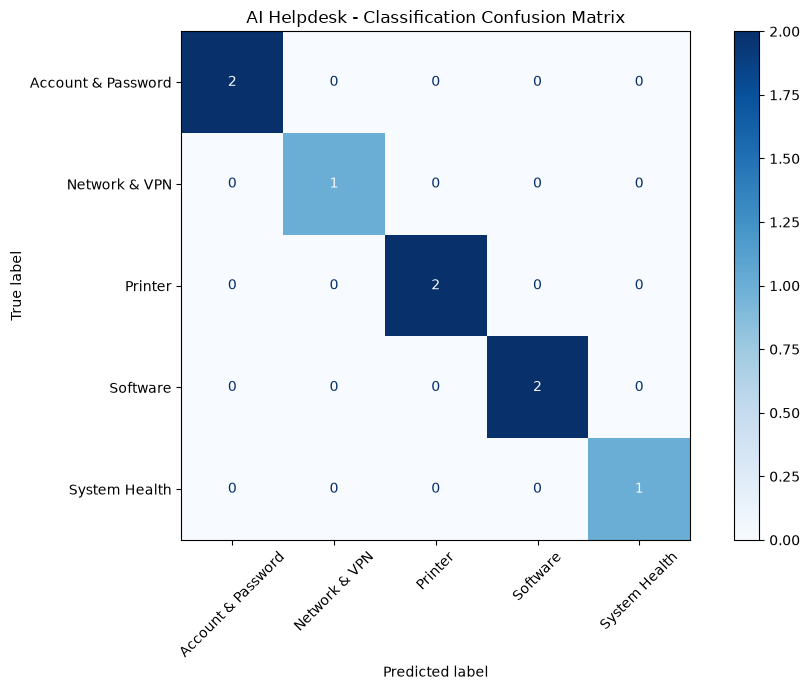

In [70]:
labels = sorted(set(y_test) | set(y_pred))

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=labels
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=labels
)

fig, ax = plt.subplots(figsize=(10, 7))

disp.plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=45,
    values_format="d"
)

plt.title("AI Helpdesk - Classification Confusion Matrix")
plt.tight_layout()
plt.show()


In [ ]:
# Inspect the knowledge base

In [71]:
from pathlib import Path
import pandas as pd

BASE_DIR = Path(r"D:\AI_IT_HELPDESK")

KB_PATH = BASE_DIR / "knowledge_base" / "it_knowledge_base.csv"

print("Knowledge Base Exists:", KB_PATH.exists())

if not KB_PATH.exists():
    raise FileNotFoundError(f"Knowledge base not found: {KB_PATH}")

kb_df = pd.read_csv(KB_PATH)

print("\nKnowledge Base Shape:", kb_df.shape)

print("\nAvailable Columns:")
print(kb_df.columns.tolist())

print("\nFirst 10 Articles:")
display(kb_df.head(10))

print("\nArticles by Category:")

# Identify the category column
category_columns = [
    col for col in kb_df.columns
    if col.lower() in ["category", "category_name"]
]

if category_columns:
    category_col = category_columns[0]
    display(kb_df[category_col].value_counts())
else:
    print("Category column not identified. Review the column names above.")


Knowledge Base Exists: True

Knowledge Base Shape: (15, 5)

Available Columns:
['id', 'category', 'title', 'content', 'source']

First 10 Articles:


,id,category,title,content,source
0,KB001,Account & Password,Windows Login Failure,\n Problem: User cannot log into Window...,Demo IT Support Knowledge Base
1,KB002,Account & Password,Password Reset,\n Problem: User forgot the Windows pas...,Demo IT Support Knowledge Base
2,KB003,Account & Password,Account Locked,\n Problem: Windows account is locked.\...,Demo IT Support Knowledge Base
3,KB004,Network & VPN,Internet Connection Failure,\n Problem: Computer cannot access the ...,Demo IT Support Knowledge Base
4,KB005,Network & VPN,VPN Connection Failure,\n Problem: User cannot connect to the ...,Demo IT Support Knowledge Base
5,KB006,Network & VPN,DNS Resolution Failure,\n Problem: DNS server is not respondin...,Demo IT Support Knowledge Base
6,KB007,Printer,Printer Offline,\n Problem: Network printer shows offli...,Demo IT Support Knowledge Base
7,KB008,Printer,Print Queue Stuck,\n Problem: Documents remain in the pri...,Demo IT Support Knowledge Base
8,KB009,Printer,Printer Driver Error,\n Problem: Printer driver is not funct...,Demo IT Support Knowledge Base
9,KB010,Software,Application Not Opening,\n Problem: Application fails to open.\...,Demo IT Support Knowledge Base



Articles by Category:


category
Account & Password    3
Network & VPN         3
Printer               3
Software              3
System Health         3
Name: count, dtype: int64

In [ ]:
#  Vector Database Inspection

In [72]:

import chromadb

VECTOR_PATH = BASE_DIR / "knowledge_base" / "vector_store"

client = chromadb.PersistentClient(
    path=str(VECTOR_PATH)
)

collections = client.list_collections()

print("Available ChromaDB Collections:")

for collection in collections:
    print("Collection:", collection.name)
    print("Number of stored records:", collection.count())

Available ChromaDB Collections:
Collection: it_helpdesk_knowledge
Number of stored records: 15


In [ ]:
# Inspect ChromaDB Records

In [73]:
import chromadb

from pathlib import Path

BASE_DIR = Path(r"D:\AI_IT_HELPDESK")
VECTOR_PATH = BASE_DIR / "knowledge_base" / "vector_store"

client = chromadb.PersistentClient(
    path=str(VECTOR_PATH)
)

collection = client.get_collection(
    name="it_helpdesk_knowledge"
)

records = collection.get(
    limit=15,
    include=["metadatas", "documents"]
)

print("Total vector records:", collection.count())

for i in range(min(5, len(records["ids"]))):
    print("\nRecord:", records["ids"][i])
    print("Metadata:", records["metadatas"][i])
    print("Document:", str(records["documents"][i])[:250])


Total vector records: 15

Record: KB001_chunk_0
Metadata: {'chunk_number': 0, 'title': 'Windows Login Failure', 'source': 'Demo IT Support Knowledge Base', 'article_id': 'KB001', 'category': 'Account & Password'}
Document: Title: Windows Login Failure Category: Account & Password Problem: User cannot log into Windows. Troubleshooting: 1. Verify the username. 2. Check keyboard layout and Caps Lock. 3. Record the displayed error message. 4. Check whether the account is l

Record: KB002_chunk_0
Metadata: {'title': 'Password Reset', 'category': 'Account & Password', 'chunk_number': 0, 'article_id': 'KB002', 'source': 'Demo IT Support Knowledge Base'}
Document: Title: Password Reset Category: Account & Password Problem: User forgot the Windows password. Troubleshooting: 1. Verify the user's identity. 2. Follow the organisation's approved password reset procedure. 3. Confirm successful authentication. 4. Nev

Record: KB003_chunk_0
Metadata: {'title': 'Account Locked', 'article_id': 'KB003', 

In [ ]:
#  RAG Retrieval Evaluation

In [74]:
import pandas as pd
from pathlib import Path
from sentence_transformers import SentenceTransformer

BASE_DIR = Path(r"D:\AI_IT_HELPDESK")
RESULTS_DIR = BASE_DIR / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Load the same embedding model used in your RAG system
embedding_model = SentenceTransformer(
    "sentence-transformers/all-MiniLM-L6-v2"
)

# Connect to existing ChromaDB collection
client = chromadb.PersistentClient(
    path=str(BASE_DIR / "knowledge_base" / "vector_store")
)

collection = client.get_collection(
    name="it_helpdesk_knowledge"
)

# Test queries and expected relevant article IDs
test_queries = [
    {
        "query": "How can I reset my Windows password?",
        "relevant_ids": ["KB002"]
    },
    {
        "query": "My printer is showing offline",
        "relevant_ids": ["KB007"]
    },
    {
        "query": "I cannot access the internet",
        "relevant_ids": ["KB004"]
    },
    {
        "query": "My office VPN is not connecting",
        "relevant_ids": ["KB005"]
    },
    {
        "query": "My application will not open",
        "relevant_ids": ["KB010"]
    }
]

evaluation_results = []

for item in test_queries:

    query = item["query"]
    relevant_ids = set(item["relevant_ids"])

    # Generate query embedding
    query_embedding = embedding_model.encode(
        [query],
        normalize_embeddings=True
    ).tolist()

    # Retrieve top 3 documents
    results = collection.query(
        query_embeddings=query_embedding,
        n_results=3
    )

    retrieved_ids = results["ids"][0]

    # Calculate retrieval metrics
    relevant_found = [
        doc_id for doc_id in retrieved_ids
        if doc_id in relevant_ids
    ]

    precision_at_3 = len(relevant_found) / 3
    recall_at_3 = len(relevant_found) / len(relevant_ids)

    reciprocal_rank = 0

    for rank, doc_id in enumerate(retrieved_ids, start=1):
        if doc_id in relevant_ids:
            reciprocal_rank = 1 / rank
            break

    evaluation_results.append({
        "Query": query,
        "Expected_IDs": ", ".join(relevant_ids),
        "Retrieved_IDs": ", ".join(retrieved_ids),
        "Precision@3": precision_at_3,
        "Recall@3": recall_at_3,
        "MRR": reciprocal_rank
    })

# Create evaluation report
rag_df = pd.DataFrame(evaluation_results)

display(rag_df)

# Calculate average metrics
print("\n===== RAG EVALUATION SUMMARY =====")

print(
    "Average Precision@3:",
    round(rag_df["Precision@3"].mean(), 4)
)

print(
    "Average Recall@3:",
    round(rag_df["Recall@3"].mean(), 4)
)

print(
    "Mean Reciprocal Rank:",
    round(rag_df["MRR"].mean(), 4)
)

# Save results
rag_df.to_csv(
    RESULTS_DIR / "rag_retrieval_evaluation_final.csv",
    index=False
)

print("\nRAG evaluation results saved successfully.")


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

,Query,Expected_IDs,Retrieved_IDs,Precision@3,Recall@3,MRR
0,How can I reset my Windows password?,KB002,"KB002_chunk_0, KB001_chunk_0, KB003_chunk_0",0.0,0.0,0
1,My printer is showing offline,KB007,"KB007_chunk_0, KB009_chunk_0, KB008_chunk_0",0.0,0.0,0
2,I cannot access the internet,KB004,"KB004_chunk_0, KB006_chunk_0, KB005_chunk_0",0.0,0.0,0
3,My office VPN is not connecting,KB005,"KB005_chunk_0, KB004_chunk_0, KB006_chunk_0",0.0,0.0,0
4,My application will not open,KB010,"KB010_chunk_0, KB012_chunk_0, KB011_chunk_0",0.0,0.0,0



===== RAG EVALUATION SUMMARY =====
Average Precision@3: 0.0
Average Recall@3: 0.0
Mean Reciprocal Rank: 0.0

RAG evaluation results saved successfully.


In [ ]:
# Corrected RAG Evaluation

In [75]:
import pandas as pd
import chromadb

from pathlib import Path
from sentence_transformers import SentenceTransformer

BASE_DIR = Path(r"D:\AI_IT_HELPDESK")
RESULTS_DIR = BASE_DIR / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Load embedding model
embedding_model = SentenceTransformer(
    "sentence-transformers/all-MiniLM-L6-v2"
)

# Connect to ChromaDB
client = chromadb.PersistentClient(
    path=str(BASE_DIR / "knowledge_base" / "vector_store")
)

collection = client.get_collection(
    name="it_helpdesk_knowledge"
)

# Evaluation queries
test_queries = [
    {
        "query": "How can I reset my Windows password?",
        "relevant_ids": ["KB002"]
    },
    {
        "query": "My printer is showing offline",
        "relevant_ids": ["KB007"]
    },
    {
        "query": "I cannot access the internet",
        "relevant_ids": ["KB004"]
    },
    {
        "query": "My office VPN is not connecting",
        "relevant_ids": ["KB005"]
    },
    {
        "query": "My application will not open",
        "relevant_ids": ["KB010"]
    }
]

evaluation_results = []

for item in test_queries:

    query = item["query"]
    relevant_ids = set(item["relevant_ids"])

    query_embedding = embedding_model.encode(
        [query],
        normalize_embeddings=True
    ).tolist()

    results = collection.query(
        query_embeddings=query_embedding,
        n_results=3,
        include=["metadatas", "distances"]
    )

    # Extract article IDs from metadata
    retrieved_ids = [
        metadata["article_id"]
        for metadata in results["metadatas"][0]
    ]

    relevant_found = [
        doc_id for doc_id in retrieved_ids
        if doc_id in relevant_ids
    ]

    precision_at_3 = len(relevant_found) / 3
    recall_at_3 = len(relevant_found) / len(relevant_ids)

    reciprocal_rank = 0

    for rank, doc_id in enumerate(retrieved_ids, start=1):
        if doc_id in relevant_ids:
            reciprocal_rank = 1 / rank
            break

    evaluation_results.append({
        "Query": query,
        "Expected_ID": ", ".join(sorted(relevant_ids)),
        "Retrieved_IDs": ", ".join(retrieved_ids),
        "Precision@3": precision_at_3,
        "Recall@3": recall_at_3,
        "MRR": reciprocal_rank
    })

# Create results DataFrame
rag_df = pd.DataFrame(evaluation_results)

print("===== RAG RETRIEVAL RESULTS =====")
display(rag_df)

# Average metrics
print("\n===== RAG EVALUATION SUMMARY =====")

print(
    "Average Precision@3:",
    round(rag_df["Precision@3"].mean(), 4)
)

print(
    "Average Recall@3:",
    round(rag_df["Recall@3"].mean(), 4)
)

print(
    "Mean Reciprocal Rank:",
    round(rag_df["MRR"].mean(), 4)
)

# Save results
output_path = RESULTS_DIR / "rag_retrieval_evaluation_final.csv"

rag_df.to_csv(output_path, index=False)

print("\nResults saved to:", output_path)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

===== RAG RETRIEVAL RESULTS =====


,Query,Expected_ID,Retrieved_IDs,Precision@3,Recall@3,MRR
0,How can I reset my Windows password?,KB002,"KB002, KB001, KB003",0.333333,1.0,1.0
1,My printer is showing offline,KB007,"KB007, KB009, KB008",0.333333,1.0,1.0
2,I cannot access the internet,KB004,"KB004, KB006, KB005",0.333333,1.0,1.0
3,My office VPN is not connecting,KB005,"KB005, KB004, KB006",0.333333,1.0,1.0
4,My application will not open,KB010,"KB010, KB012, KB011",0.333333,1.0,1.0



===== RAG EVALUATION SUMMARY =====
Average Precision@3: 0.3333
Average Recall@3: 1.0
Mean Reciprocal Rank: 1.0

Results saved to: D:\AI_IT_HELPDESK\results\rag_retrieval_evaluation_final.csv


In [ ]:
#  Combined AI Evaluation Report

In [76]:
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

BASE_DIR = Path(r"D:\AI_IT_HELPDESK")
RESULTS_DIR = BASE_DIR / "results"

# Load classification predictions
classification_path = (
    RESULTS_DIR / "ai_classification_predictions.csv"
)

# Load RAG results
rag_path = (
    RESULTS_DIR / "rag_retrieval_evaluation_final.csv"
)

classification_df = pd.read_csv(classification_path)
rag_df = pd.read_csv(rag_path)

# Classification metrics
actual = classification_df["Actual Category"]
predicted = classification_df["Predicted Category"]

classification_metrics = {
    "Accuracy": accuracy_score(actual, predicted),
    "Macro Precision": precision_score(
        actual, predicted, average="macro", zero_division=0
    ),
    "Macro Recall": recall_score(
        actual, predicted, average="macro", zero_division=0
    ),
    "Macro F1": f1_score(
        actual, predicted, average="macro", zero_division=0
    )
}

# RAG metrics
rag_metrics = {
    "Precision@3": rag_df["Precision@3"].mean(),
    "Recall@3": rag_df["Recall@3"].mean(),
    "MRR": rag_df["MRR"].mean()
}

# Combined report
combined_df = pd.DataFrame([
    {
        "Component": "AI Classification",
        "Metric": metric,
        "Score": score
    }
    for metric, score in classification_metrics.items()
] + [
    {
        "Component": "RAG Retrieval",
        "Metric": metric,
        "Score": score
    }
    for metric, score in rag_metrics.items()
])

print("===== COMBINED AI EVALUATION =====")
display(combined_df)

# Save report
report_path = RESULTS_DIR / "combined_ai_evaluation.csv"

combined_df.to_csv(report_path, index=False)

print("Combined report saved:", report_path)


===== COMBINED AI EVALUATION =====


,Component,Metric,Score
0,AI Classification,Accuracy,1.000000
1,AI Classification,Macro Precision,1.000000
2,AI Classification,Macro Recall,1.000000
3,AI Classification,Macro F1,1.000000
4,RAG Retrieval,Precision@3,0.333333
5,RAG Retrieval,Recall@3,1.000000
6,RAG Retrieval,MRR,1.000000


Combined report saved: D:\AI_IT_HELPDESK\results\combined_ai_evaluation.csv


In [ ]:
# AI Evaluation Chart

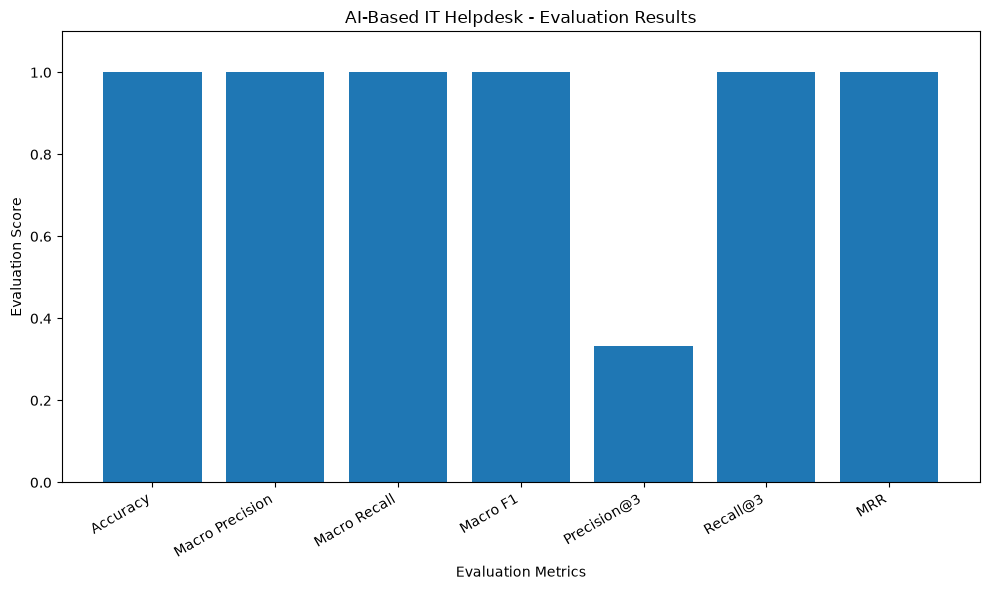

In [77]:
plt.figure(figsize=(10, 6))

plt.bar(
    combined_df["Metric"],
    combined_df["Score"]
)

plt.title("AI-Based IT Helpdesk - Evaluation Results")
plt.ylabel("Evaluation Score")
plt.xlabel("Evaluation Metrics")

plt.ylim(0, 1.1)
plt.xticks(rotation=30, ha="right")

plt.tight_layout()

chart_path = RESULTS_DIR / "combined_ai_evaluation_chart.png"

In [ ]:
# Create Expanded Classification Test Template

In [78]:
import pandas as pd
from pathlib import Path

BASE_DIR = Path(r"D:\AI_IT_HELPDESK")
RESULTS_DIR = BASE_DIR / "results"
DATASET_DIR = BASE_DIR / "dataset" / "processed"

categories = [
    "Account & Password",
    "Network & VPN",
    "Printer",
    "Software",
    "System Health"
]

# Create a blank independent evaluation template
test_template = pd.DataFrame({
    "Test_ID": [f"EXT{i:03d}" for i in range(1, 51)],
    "user_query": [""] * 50,
    "category": [
        category
        for category in categories
        for _ in range(10)
    ]
})

output_path = (
    DATASET_DIR / "expanded_classification_test_template.csv"
)

test_template.to_csv(output_path, index=False)

print("Expanded test template created.")
print("Total records:", len(test_template))
print("\nRecords per category:")
print(test_template["category"].value_counts())

print("\nFile saved:", output_path)


Expanded test template created.
Total records: 50

Records per category:
category
Account & Password    10
Network & VPN         10
Printer               10
Software              10
System Health         10
Name: count, dtype: int64

File saved: D:\AI_IT_HELPDESK\dataset\processed\expanded_classification_test_template.csv


In [ ]:
# Populate the expanded test dataset

In [79]:
import pandas as pd
from pathlib import Path

BASE_DIR = Path(r"D:\AI_IT_HELPDESK")
TEST_PATH = (
    BASE_DIR / "dataset" / "processed" /
    "expanded_classification_test_template.csv"
)

test_queries = {
    "Account & Password": [
        "I cannot remember my Windows login password.",
        "My domain account says the password has expired.",
        "My account is locked after several failed login attempts.",
        "I cannot sign in to my computer using my domain credentials.",
        "How can I change my current Windows password?",
        "My username and password are not being accepted.",
        "I need assistance resetting my Microsoft 365 password.",
        "My account has been disabled and I cannot log in.",
        "I can log in to Windows but cannot access my work account.",
        "I am getting an authentication error when signing in."
    ],
    "Network & VPN": [
        "My computer is connected to WiFi but websites do not load.",
        "I cannot connect to the company VPN from home.",
        "The office network connection keeps disconnecting.",
        "I cannot access the internal company website.",
        "My network adapter is showing an unidentified network.",
        "I cannot access shared folders on the office network.",
        "The VPN client gets stuck while connecting.",
        "My computer is receiving an invalid IP address.",
        "Internet access is very slow on my office computer.",
        "I am getting a DNS server not responding error."
    ],
    "Printer": [
        "The network printer is not appearing on my computer.",
        "My printer displays an offline status.",
        "Documents are stuck in the Windows print queue.",
        "The printer is producing blank pages.",
        "I cannot install the office printer driver.",
        "My computer cannot communicate with the network printer.",
        "The printer is showing a paper jam warning.",
        "Print jobs are taking too long to complete.",
        "I cannot print PDF documents from my computer.",
        "The printer driver installation failed."
    ],
    "Software": [
        "Microsoft Excel closes unexpectedly when I open a workbook.",
        "The application freezes whenever I try to save a file.",
        "I receive an error when launching the company application.",
        "Microsoft Outlook is not opening on my computer.",
        "The software installation process keeps failing.",
        "An application displays a missing DLL error.",
        "My browser crashes when accessing the internal system.",
        "The application is responding very slowly.",
        "I cannot update the installed software.",
        "The program reports that it has stopped working."
    ],
    "System Health": [
        "My computer is running out of disk space.",
        "The laptop becomes very slow after startup.",
        "My computer overheats during normal operation.",
        "The system restarts automatically without warning.",
        "CPU usage remains at 100 percent.",
        "My laptop battery drains very quickly.",
        "Windows takes a long time to boot.",
        "The computer frequently displays a blue screen.",
        "RAM usage is unusually high when no applications are open.",
        "My laptop shuts down unexpectedly."
    ]
}

rows = []

for category, queries in test_queries.items():
    for query in queries:
        rows.append({
            "user_query": query,
            "category": category
        })

expanded_df = pd.DataFrame(rows)

expanded_df.insert(
    0,
    "Test_ID",
    [f"EXT{i:03d}" for i in range(1, len(expanded_df) + 1)]
)

expanded_df.to_csv(TEST_PATH, index=False)

print("Expanded test dataset populated.")
print("Total records:", len(expanded_df))
print("\nCategory distribution:")
print(expanded_df["category"].value_counts())
print("\nMissing queries:", expanded_df["user_query"].isna().sum())
print("Saved to:", TEST_PATH)

display(expanded_df.head(10))


Expanded test dataset populated.
Total records: 50

Category distribution:
category
Account & Password    10
Network & VPN         10
Printer               10
Software              10
System Health         10
Name: count, dtype: int64

Missing queries: 0
Saved to: D:\AI_IT_HELPDESK\dataset\processed\expanded_classification_test_template.csv


,Test_ID,user_query,category
0,EXT001,I cannot remember my Windows login password.,Account & Password
1,EXT002,My domain account says the password has expired.,Account & Password
2,EXT003,My account is locked after several failed logi...,Account & Password
3,EXT004,I cannot sign in to my computer using my domai...,Account & Password
4,EXT005,How can I change my current Windows password?,Account & Password
5,EXT006,My username and password are not being accepted.,Account & Password
6,EXT007,I need assistance resetting my Microsoft 365 p...,Account & Password
7,EXT008,My account has been disabled and I cannot log in.,Account & Password
8,EXT009,I can log in to Windows but cannot access my w...,Account & Password
9,EXT010,I am getting an authentication error when sign...,Account & Password


In [ ]:
#  Expanded AI Classification Evaluation

Model loaded successfully.
Test records: 50

===== EXPANDED AI CLASSIFICATION EVALUATION =====
Accuracy       : 0.7800
Macro Precision: 0.8217
Macro Recall   : 0.7800
Macro F1-score : 0.7883

===== CLASSIFICATION REPORT =====
                    precision    recall  f1-score   support

Account & Password       0.90      0.90      0.90        10
     Network & VPN       0.80      0.80      0.80        10
           Printer       0.88      0.70      0.78        10
          Software       1.00      0.70      0.82        10
     System Health       0.53      0.80      0.64        10

          accuracy                           0.78        50
         macro avg       0.82      0.78      0.79        50
      weighted avg       0.82      0.78      0.79        50


Predictions saved to: D:\AI_IT_HELPDESK\results\expanded_classification_predictions.csv

Incorrect predictions: 11


,Test_ID,user_query,category,predicted_category
9,EXT010,I am getting an authentication error when sign...,Account & Password,Printer
10,EXT011,My computer is connected to WiFi but websites ...,Network & VPN,System Health
17,EXT018,My computer is receiving an invalid IP address.,Network & VPN,System Health
25,EXT026,My computer cannot communicate with the networ...,Printer,Network & VPN
27,EXT028,Print jobs are taking too long to complete.,Printer,System Health
28,EXT029,I cannot print PDF documents from my computer.,Printer,System Health
30,EXT031,Microsoft Excel closes unexpectedly when I ope...,Software,System Health
33,EXT034,Microsoft Outlook is not opening on my computer.,Software,System Health
36,EXT037,My browser crashes when accessing the internal...,Software,System Health
41,EXT042,The laptop becomes very slow after startup.,System Health,Network & VPN


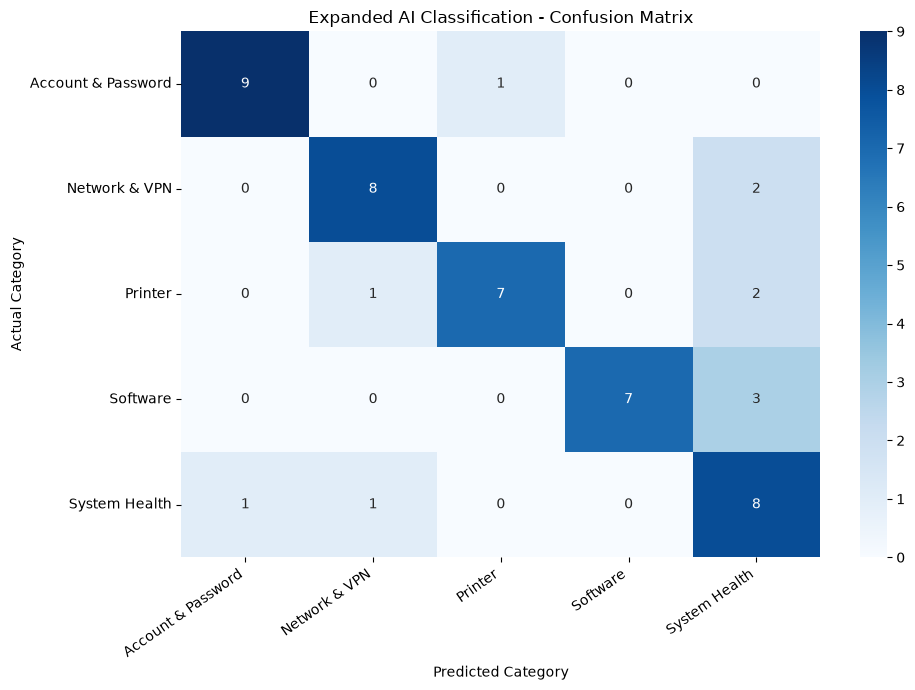


===== CATEGORY-WISE ACCURACY =====


,category,Accuracy_Percentage
0,Account & Password,90.0
1,Network & VPN,80.0
2,Printer,70.0
3,Software,70.0
4,System Health,80.0


In [80]:
import pandas as pd
import joblib
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Project paths
BASE_DIR = Path(r"D:\AI_IT_HELPDESK")

MODEL_PATH = BASE_DIR / "models" / "it_helpdesk_classifier.pkl"

TEST_PATH = (
    BASE_DIR / "dataset" / "processed" /
    "expanded_classification_test_template.csv"
)

RESULT_PATH = (
    BASE_DIR / "results" /
    "expanded_classification_predictions.csv"
)

# Load existing model and test dataset
model = joblib.load(MODEL_PATH)
test_df = pd.read_csv(TEST_PATH)

print("Model loaded successfully.")
print("Test records:", len(test_df))

# Generate predictions
X_test = test_df["user_query"]
y_actual = test_df["category"]

y_predicted = model.predict(X_test)

# Store predictions
results_df = test_df.copy()
results_df["predicted_category"] = y_predicted
results_df["correct"] = (
    results_df["category"] == results_df["predicted_category"]
)

# Calculate evaluation metrics
accuracy = accuracy_score(y_actual, y_predicted)

precision = precision_score(
    y_actual, y_predicted, average="macro", zero_division=0
)

recall = recall_score(
    y_actual, y_predicted, average="macro", zero_division=0
)

f1 = f1_score(
    y_actual, y_predicted, average="macro", zero_division=0
)

print("\n===== EXPANDED AI CLASSIFICATION EVALUATION =====")
print(f"Accuracy       : {accuracy:.4f}")
print(f"Macro Precision: {precision:.4f}")
print(f"Macro Recall   : {recall:.4f}")
print(f"Macro F1-score : {f1:.4f}")

print("\n===== CLASSIFICATION REPORT =====")
print(
    classification_report(
        y_actual,
        y_predicted,
        zero_division=0
    )
)

# Save detailed predictions
results_df.to_csv(RESULT_PATH, index=False)

print("\nPredictions saved to:", RESULT_PATH)

# Display incorrect predictions
incorrect_df = results_df[
    results_df["correct"] == False
]

print("\nIncorrect predictions:", len(incorrect_df))

display(
    incorrect_df[
        ["Test_ID", "user_query", "category", "predicted_category"]
    ]
)

# Confusion matrix
labels = sorted(set(y_actual) | set(y_predicted))

cm = confusion_matrix(
    y_actual,
    y_predicted,
    labels=labels
)

plt.figure(figsize=(10, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels
)

plt.title("Expanded AI Classification - Confusion Matrix")
plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")
plt.xticks(rotation=35, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# Accuracy by category
category_accuracy = (
    results_df.groupby("category")["correct"]
    .mean()
    .mul(100)
    .reset_index(name="Accuracy_Percentage")
)

print("\n===== CATEGORY-WISE ACCURACY =====")
display(category_accuracy)


In [ ]:
#  Classification Error Analysis

In [81]:
import pandas as pd
from pathlib import Path

BASE_DIR = Path(r"D:\AI_IT_HELPDESK")

RESULT_PATH = (
    BASE_DIR / "results" /
    "expanded_classification_predictions.csv"
)

ERROR_PATH = (
    BASE_DIR / "results" /
    "classification_error_analysis.csv"
)

df = pd.read_csv(RESULT_PATH)

# Select incorrect predictions
errors = df[df["correct"] == False].copy()

# Add error type
errors["error_type"] = (
    errors["category"].astype(str)
    + " -> "
    + errors["predicted_category"].astype(str)
)

# Count confusion patterns
error_summary = (
    errors.groupby("error_type")
    .size()
    .reset_index(name="error_count")
    .sort_values("error_count", ascending=False)
)

print("===== CLASSIFICATION ERROR SUMMARY =====")
display(error_summary)

print("\n===== INCORRECT PREDICTIONS =====")
display(
    errors[
        [
            "Test_ID",
            "user_query",
            "category",
            "predicted_category"
        ]
    ]
)

errors.to_csv(ERROR_PATH, index=False)

print("\nError analysis saved to:")
print(ERROR_PATH)

print("\nTotal errors:", len(errors))


===== CLASSIFICATION ERROR SUMMARY =====


,error_type,error_count
4,Software -> System Health,3
3,Printer -> System Health,2
1,Network & VPN -> System Health,2
2,Printer -> Network & VPN,1
0,Account & Password -> Printer,1
5,System Health -> Account & Password,1
6,System Health -> Network & VPN,1



===== INCORRECT PREDICTIONS =====


,Test_ID,user_query,category,predicted_category
9,EXT010,I am getting an authentication error when sign...,Account & Password,Printer
10,EXT011,My computer is connected to WiFi but websites ...,Network & VPN,System Health
17,EXT018,My computer is receiving an invalid IP address.,Network & VPN,System Health
25,EXT026,My computer cannot communicate with the networ...,Printer,Network & VPN
27,EXT028,Print jobs are taking too long to complete.,Printer,System Health
28,EXT029,I cannot print PDF documents from my computer.,Printer,System Health
30,EXT031,Microsoft Excel closes unexpectedly when I ope...,Software,System Health
33,EXT034,Microsoft Outlook is not opening on my computer.,Software,System Health
36,EXT037,My browser crashes when accessing the internal...,Software,System Health
41,EXT042,The laptop becomes very slow after startup.,System Health,Network & VPN



Error analysis saved to:
D:\AI_IT_HELPDESK\results\classification_error_analysis.csv

Total errors: 11


In [ ]:
# Create additional training examples

In [82]:
import pandas as pd
from pathlib import Path

BASE_DIR = Path(r"D:\AI_IT_HELPDESK")

OUTPUT_PATH = (
    BASE_DIR / "dataset" / "processed" /
    "additional_training_data.csv"
)

additional_data = {
    "Account & Password": [
        "I cannot authenticate using my company username.",
        "My Windows account password is no longer valid.",
        "The login screen rejects my correct password.",
        "I need to unlock my domain user account.",
        "I cannot sign in after changing my password.",
        "My Microsoft 365 account keeps requesting credentials.",
        "The system says my user account is disabled.",
        "I am unable to access my profile because of a login error.",
        "My account is locked following multiple incorrect passwords.",
        "I receive an authentication failure when logging in.",
        "Windows asks me to enter my credentials repeatedly.",
        "I cannot access my computer using my domain account.",
        "My password reset request is not working.",
        "The account sign-in process keeps failing.",
        "I receive an invalid credentials notification.",
        "My account cannot be authenticated by the domain.",
        "I cannot access my work email due to a password issue.",
        "The system does not recognise my username.",
        "I am unable to change my expired password.",
        "My user account has been blocked."
    ],

    "Network & VPN": [
        "My laptop cannot connect to the office network.",
        "The company VPN connection fails repeatedly.",
        "I cannot browse websites despite being connected to WiFi.",
        "The network connection keeps dropping.",
        "I cannot access internal company servers.",
        "My computer cannot obtain an IP address.",
        "The DNS lookup is failing on my computer.",
        "I cannot connect to the corporate VPN server.",
        "My internet connection is unavailable.",
        "The network adapter reports limited connectivity.",
        "I cannot open shared network drives.",
        "The VPN client reports a connection timeout.",
        "The office network is extremely slow.",
        "My computer cannot reach the gateway.",
        "Internal websites are unavailable over the network.",
        "The WiFi connection disconnects frequently.",
        "I receive a network path not found error.",
        "My computer cannot communicate with the router.",
        "The VPN authentication server cannot be reached.",
        "I cannot access the internet from my office PC."
    ],

    "Printer": [
        "My office printer is showing as offline.",
        "The printer is not responding to print commands.",
        "My print jobs remain stuck in the queue.",
        "I cannot find the shared network printer.",
        "The printer driver is missing from Windows.",
        "The printer produces blank documents.",
        "My printer cannot connect to its network address.",
        "The printer displays a paper jam message.",
        "I cannot print documents from Microsoft Word.",
        "The printer installation failed.",
        "The printer is printing very slowly.",
        "My computer cannot detect the USB printer.",
        "The print spooler service has stopped.",
        "PDF printing fails on the office printer.",
        "The printer displays an error status.",
        "The printer is not accepting new jobs.",
        "I cannot install the network printer.",
        "The printer keeps disconnecting from Windows.",
        "My documents are not coming out of the printer.",
        "The printer driver is reporting an error."
    ],

    "Software": [
        "Microsoft Excel crashes when opening a spreadsheet.",
        "Outlook fails to launch after clicking its icon.",
        "The business application freezes during data entry.",
        "The installed application displays an unexpected error.",
        "My browser crashes when opening a web application.",
        "The software installation wizard cannot complete.",
        "Microsoft Word stops responding when saving documents.",
        "The application reports a missing DLL file.",
        "I cannot update the installed business software.",
        "The application closes immediately after startup.",
        "A program is displaying an application error.",
        "My software is not responding to keyboard input.",
        "The company application cannot load its main screen.",
        "The application crashes when processing a transaction.",
        "The browser displays a script error.",
        "The software update fails during installation.",
        "I receive an error when opening a PDF application.",
        "The application is stuck on its loading screen.",
        "Microsoft Teams is not starting correctly.",
        "The software displays an unexpected runtime error."
    ],

    "System Health": [
        "My computer is running slowly after startup.",
        "The laptop overheats during normal usage.",
        "Windows takes too long to boot.",
        "My computer shuts down unexpectedly.",
        "The system memory usage is unusually high.",
        "My laptop battery drains very quickly.",
        "The hard disk is almost full.",
        "CPU usage remains very high even when idle.",
        "The computer frequently displays a blue screen.",
        "My laptop restarts without warning.",
        "Windows startup takes several minutes.",
        "The computer becomes unresponsive during normal use.",
        "My laptop fan runs continuously at high speed.",
        "The system reports insufficient disk space.",
        "The computer performance has decreased significantly.",
        "My device freezes even without opening applications.",
        "The laptop becomes hot and shuts down.",
        "Windows reports a hardware-related error.",
        "The computer has very little available RAM.",
        "My laptop takes a long time to become usable."
    ]
}

# Convert examples into a DataFrame
new_rows = []

for category, queries in additional_data.items():
    for query in queries:
        new_rows.append({
            "user_query": query,
            "category": category
        })

additional_df = pd.DataFrame(new_rows)

additional_df.insert(
    0,
    "Training_ID",
    [f"ADD{i:03d}" for i in range(1, len(additional_df) + 1)]
)

# Save without modifying the original datasets
additional_df.to_csv(OUTPUT_PATH, index=False)

print("Additional training dataset created.")
print("Total records:", len(additional_df))

print("\nCategory distribution:")
print(additional_df["category"].value_counts())

print("\nMissing values:")
print(additional_df.isnull().sum())

print("\nSaved to:", OUTPUT_PATH)

display(additional_df.head(10))


Additional training dataset created.
Total records: 100

Category distribution:
category
Account & Password    20
Network & VPN         20
Printer               20
Software              20
System Health         20
Name: count, dtype: int64

Missing values:
Training_ID    0
user_query     0
category       0
dtype: int64

Saved to: D:\AI_IT_HELPDESK\dataset\processed\additional_training_data.csv


,Training_ID,user_query,category
0,ADD001,I cannot authenticate using my company username.,Account & Password
1,ADD002,My Windows account password is no longer valid.,Account & Password
2,ADD003,The login screen rejects my correct password.,Account & Password
3,ADD004,I need to unlock my domain user account.,Account & Password
4,ADD005,I cannot sign in after changing my password.,Account & Password
5,ADD006,My Microsoft 365 account keeps requesting cred...,Account & Password
6,ADD007,The system says my user account is disabled.,Account & Password
7,ADD008,I am unable to access my profile because of a ...,Account & Password
8,ADD009,My account is locked following multiple incorr...,Account & Password
9,ADD010,I receive an authentication failure when loggi...,Account & Password


In [ ]:
#  Merge and validate training datasets

In [83]:
import pandas as pd
from pathlib import Path

BASE_DIR = Path(r"D:\AI_IT_HELPDESK")

ORIGINAL_PATH = (
    BASE_DIR / "dataset" / "processed" /
    "train_dataset.csv"
)

ADDITIONAL_PATH = (
    BASE_DIR / "dataset" / "processed" /
    "additional_training_data.csv"
)

MERGED_PATH = (
    BASE_DIR / "dataset" / "processed" /
    "improved_training_dataset.csv"
)

# Load datasets
original_df = pd.read_csv(ORIGINAL_PATH)
additional_df = pd.read_csv(ADDITIONAL_PATH)

# Standardise required columns
original_df = original_df[["user_query", "category"]].copy()
additional_df = additional_df[["user_query", "category"]].copy()

# Combine datasets
combined_df = pd.concat(
    [original_df, additional_df],
    ignore_index=True
)

# Clean text for duplicate detection
combined_df["user_query"] = (
    combined_df["user_query"].astype(str).str.strip()
)

combined_df["category"] = (
    combined_df["category"].astype(str).str.strip()
)

combined_df["query_key"] = (
    combined_df["user_query"].str.lower()
)

# Identify duplicate queries
duplicate_df = combined_df[
    combined_df.duplicated("query_key", keep=False)
].copy()

# Keep one copy of each query
merged_df = combined_df.drop_duplicates(
    subset=["query_key"],
    keep="first"
).drop(columns=["query_key"])

# Check missing values
print("===== DATASET MERGE SUMMARY =====")
print("Original records:", len(original_df))
print("Additional records:", len(additional_df))
print("Combined records:", len(combined_df))
print("Duplicate query rows:", len(duplicate_df))
print("Final unique records:", len(merged_df))

print("\n===== CATEGORY DISTRIBUTION =====")
display(merged_df["category"].value_counts())

print("\n===== MISSING VALUES =====")
print(merged_df.isnull().sum())

# Save improved dataset
merged_df.to_csv(MERGED_PATH, index=False)

print("\nImproved training dataset saved:")
print(MERGED_PATH)

if len(duplicate_df) > 0:
    print("\nReview duplicate queries:")
    display(duplicate_df[["user_query", "category"]])


===== DATASET MERGE SUMMARY =====
Original records: 35
Additional records: 100
Combined records: 135
Duplicate query rows: 0
Final unique records: 135

===== CATEGORY DISTRIBUTION =====


category
Printer               27
Account & Password    27
Network & VPN         27
System Health         27
Software              27
Name: count, dtype: int64


===== MISSING VALUES =====
user_query    0
category      0
dtype: int64

Improved training dataset saved:
D:\AI_IT_HELPDESK\dataset\processed\improved_training_dataset.csv
